# Семинар 1. Вариационные автоэнкодеры и генеративно-состязательные сети

**Газпром · 90 минут · Python и основы нейросетей**

- Формат: выполнение готового кода, изменение параметров, анализ результатов.
- Темы: реконструкция и генерация; prior и posterior; VAE; GAN; image-to-image.
- Сравнение: AE — реконструкция; VAE — латентное распределение; GAN — состязательное обучение; cVAE/cGAN — управление классом.
- **Вопрос занятия:** как перейти от реконструкции изображения к генерации нового объекта и управлению его классом?
- **Маршрут разбора:** разделы 1–5 → 7 → 9 и «Практика 1» → фотографии TAESD → сравнение. CycleGAN и подробные диагностики — дополнительно.

| Минуты | Основной материал |
|---|---|
| 0–5 | Стартовый резерв: Colab и «Выполнить все» в фоне |
| 5–12 | AE: реконструкция и случайные коды |
| 12–33 | VAE: prior/posterior, репараметризация, генерация |
| 33–50 | GAN: другой критерий и два шага обновления |
| 50–65 | Условие класса: один короткий самостоятельный опыт |
| 65–72 | Фотографии: демонстрация TAESD |
| 72–80 | Сравнение и контрольные вопросы |
| 80–90 | Резерв на вопросы и задержки |

**Colab:** «Файл → Загрузить блокнот» → «Среда выполнения → Выполнить все». Для обучения свёрточных сетей рекомендуется GPU; CPU поддерживается. При отсутствии библиотек:

```python
%pip install torch numpy matplotlib scikit-learn
```

- Основные данные MNIST загружаются один раз (~12 MB); новый inference CycleGAN требует сети. Сохранённый результат встроен.
- **Проведение:** 75 минут основного материала + 15 минут резерва. Один самостоятельный опыт. «Выполнить все» выполняется один раз и включает дополнительные зависимости (в частности, probe для cVAE). Дополнителен разбор, а не первый запуск этих ячеек.
- Если подключение задержалось более чем на 5 минут, продолжить по сохранённым outputs. На занятии повторять только короткую «Практику 1»; обучение и перебор β не повторять.
- `SEMINAR_QUICK=1` — сокращённая проверка исполнения; качество моделей в этом режиме не оценивается.

In [1]:
import os
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

SEED = 42
QUICK = os.environ.get("SEMINAR_QUICK", "0") == "1"
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
device = torch.device(os.environ.get("SEMINAR_DEVICE", "cuda" if torch.cuda.is_available() else "cpu"))
plt.rcParams.update({"figure.dpi": 140, "axes.spines.top": False, "axes.spines.right": False})
print(f"Device: {device}; PyTorch: {torch.__version__}; quick mode: {QUICK}")

Device: mps; PyTorch: 2.14.1; quick mode: False


## 1. Данные

- MNIST: 60 000 train / 10 000 test; используются 12 000 / 2 000 изображений, 28×28 пикселей; $x\in\mathbb R^{784}$.
- Нормировка: 0…255 → $[0,1]$.
- Метки не передаются безусловным генеративным моделям.
- Разбиение train/test предшествует обучению; test исключён из обновлений.
- Ограничение: результаты малых изображений не характеризуют качество на фотографиях.

Train: torch.Size([12000, 784]); held-out: torch.Size([2000, 784])


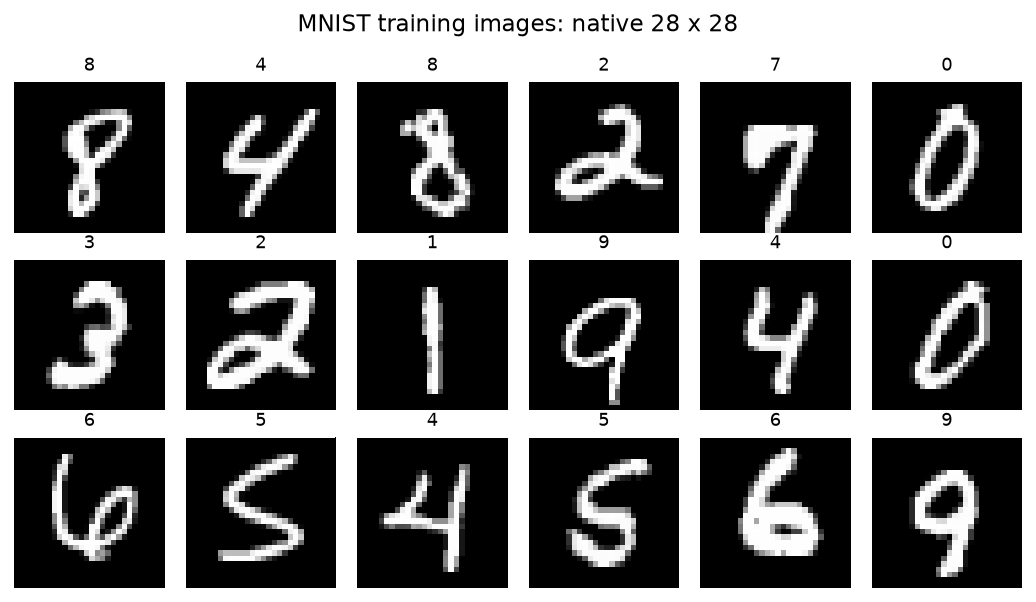

In [2]:
"""Load native-resolution MNIST with a small verified download cache."""

from pathlib import Path
import gzip
import hashlib
import struct
import urllib.request

import numpy as np
from sklearn.model_selection import train_test_split

MNIST_FILES = {
    "train-images-idx3-ubyte.gz": "f68b3c2dcbeaaa9fbdd348bbdeb94873",
    "train-labels-idx1-ubyte.gz": "d53e105ee54ea40749a09fcbcd1e9432",
    "t10k-images-idx3-ubyte.gz": "9fb629c4189551a2d022fa330f9573f3",
    "t10k-labels-idx1-ubyte.gz": "ec29112dd5afa0611ce80d1b7f02629c",
}


def load_mnist(cache="data/mnist", train_limit=12000, test_limit=2000, seed=42):
    cache = Path(cache)
    cache.mkdir(parents=True, exist_ok=True)
    arrays = {}
    for filename, expected in MNIST_FILES.items():
        path = cache / filename
        if not path.exists():
            url = "https://storage.googleapis.com/cvdf-datasets/mnist/" + filename
            with urllib.request.urlopen(url, timeout=90) as response:
                path.write_bytes(response.read())
        if hashlib.md5(path.read_bytes()).hexdigest() != expected:
            raise ValueError(f"MNIST checksum mismatch: {filename}; remove the cached file and rerun")
        payload = gzip.decompress(path.read_bytes())
        magic, count = struct.unpack(">II", payload[:8])
        if magic == 2051:
            rows, cols = struct.unpack(">II", payload[8:16])
            assert (rows, cols) == (28, 28)
            values = np.frombuffer(payload, dtype=np.uint8, offset=16).reshape(count, rows, cols)
        elif magic == 2049:
            values = np.frombuffer(payload, dtype=np.uint8, offset=8)
            assert len(values) == count
        else:
            raise ValueError(f"Unexpected MNIST magic: {magic}")
        arrays[filename] = values

    def subset(images, labels, limit):
        assert len(images) == len(labels)
        indices, _ = train_test_split(np.arange(len(labels)), train_size=limit,
                                      stratify=labels, random_state=seed)
        return images[indices].astype("float32").reshape(-1, 784) / 255.0, labels[indices].astype("int64")

    train_x, train_y = subset(arrays["train-images-idx3-ubyte.gz"], arrays["train-labels-idx1-ubyte.gz"], train_limit)
    test_x, test_y = subset(arrays["t10k-images-idx3-ubyte.gz"], arrays["t10k-labels-idx1-ubyte.gz"], test_limit)
    return train_x, test_x, train_y, test_y

IMAGE_SIZE = 28
INPUT_DIM = IMAGE_SIZE ** 2
x_train_np, x_test_np, y_train_np, y_test_np = load_mnist(train_limit=1000 if QUICK else 12000, test_limit=400 if QUICK else 2000, seed=SEED)
x_train, x_test = torch.tensor(x_train_np), torch.tensor(x_test_np)
y_train, y_test = torch.tensor(y_train_np), torch.tensor(y_test_np)
assert x_train.shape[1] == 784
loader = DataLoader(TensorDataset(x_train, y_train), batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(SEED), num_workers=0)

def image_grid(images, title, columns=10, labels=None, vmin=0.0, vmax=1.0, row_labels=None):
    values = torch.as_tensor(images).detach().cpu().numpy().reshape(-1, IMAGE_SIZE, IMAGE_SIZE)
    rows = int(np.ceil(len(values) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(columns * 1.25, rows * 1.45), squeeze=False)
    for index, axis in enumerate(axes.flat):
        axis.axis("off")
        if index < len(values):
            axis.imshow(values[index], cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
            if labels is not None:
                axis.set_title(str(labels[index]), fontsize=9)
            if row_labels is not None and index % columns == 0:
                label = row_labels[index // columns]
                label = f"y={label}" if isinstance(label, int) else str(label)
                axis.text(-0.12, 0.5, label, transform=axis.transAxes, ha="right", va="center", fontsize=11)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


print(f"Train: {x_train.shape}; held-out: {x_test.shape}")
image_grid(x_train[:18], "MNIST training images: native 28 x 28", columns=6, labels=y_train[:18].tolist())

## 2. Автоэнкодер: базовая модель

**Логика развития:** сначала восстановим наблюдаемую цифру. Затем проверим случайные коды: одной реконструкции недостаточно для генерации. VAE задаёт prior и вероятностную модель; GAN вводит другой критерий обучения. Метка класса добавляет управление. Семейства развивались параллельно; единого победителя нет.

- Encoder $e_\phi$: изображение → код; decoder $g_\theta$: код → реконструкция.
- $B$ — размер батча; $\phi,\theta$ — параметры сетей.
- `Sigmoid` ограничивает выход диапазоном $[0,1]$.

$$x:\ [B,784]\ \longrightarrow\ z:\ [B,16]\ \longrightarrow\ \hat x:\ [B,784].$$

$$\min_{\phi,\theta}\;\mathbb E_{x\sim p_{\rm data}}\left[\sum_{j=1}^{784}(x_j-g_\theta(e_\phi(x))_j)^2\right].$$

**Эксперимент:** сравнить реконструкции test-изображений и декодирование нормального шума.

**Ограничение:** AE не согласовывает распределение кодов с $\mathcal N(0,I)$.

**Теория:** [Автоэнкодеры](https://fpakhurov.com/ru/notes/generative-models/autoencoders/).

AE: 10 epochs in 3.4 s; final train SSE/image: 16.885


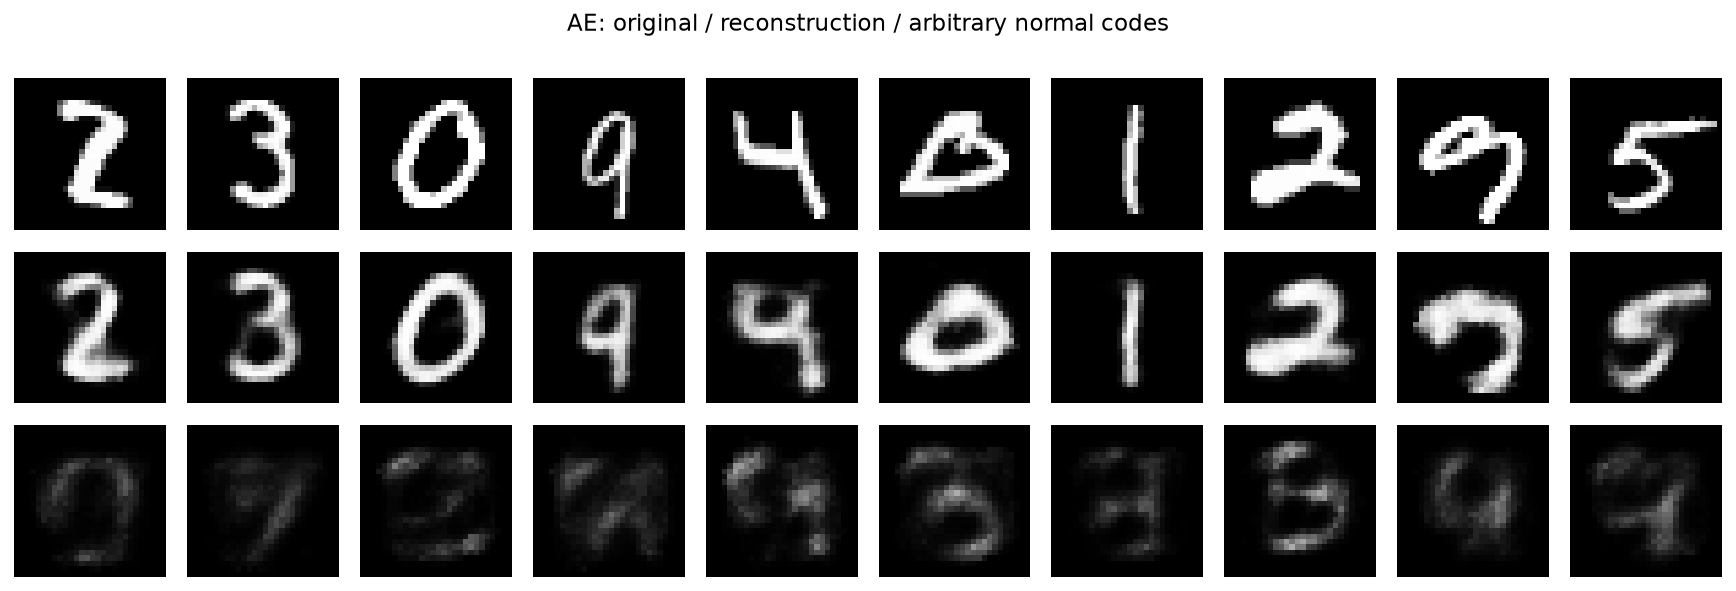

In [3]:
LATENT_DIM = 16
AE_EPOCHS = 3 if QUICK else 10


class Autoencoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(INPUT_DIM, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, INPUT_DIM), nn.Sigmoid())

    def forward(self, x):
        return self.decoder(self.encoder(x))


ae = Autoencoder().to(device)
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=2e-3)
ae_history = []
started = time.perf_counter()
for epoch in range(AE_EPOCHS):
    ae.train()
    losses = []
    for xb, _ in loader:
        xb = xb.to(device)
        reconstruction = ae(xb)
        loss = (reconstruction - xb).square().sum(dim=1).mean()
        ae_optimizer.zero_grad(set_to_none=True)
        loss.backward()
        ae_optimizer.step()
        losses.append(loss.item())
    ae_history.append(float(np.mean(losses)))
print(f"AE: {AE_EPOCHS} epochs in {time.perf_counter() - started:.1f} s; final train SSE/image: {ae_history[-1]:.3f}")
ae.eval()
with torch.no_grad():
    ae_reconstruction = ae(x_test[:20].to(device)).cpu()
    ae_random = ae.decoder(torch.randn(20, LATENT_DIM, device=device)).cpu()
image_grid(torch.cat([x_test[:10], ae_reconstruction[:10], ae_random[:10]]),
           "AE: original / reconstruction / arbitrary normal codes")

- Строки результата: оригинал → реконструкция → декодирование произвольных нормальных кодов.
- Низкая ошибка реконструкции не гарантирует качественную генерацию.

<details><summary>Дополнительно: размер кода</summary>

Изменить `LATENT_DIM` на 32; пересоздать модель и повторить обучение. Сравнить реконструкции и случайные генерации. Расширение кода не задаёт его распределение. После эксперимента восстановить исходную настройку.

</details>

## 3. Априорное и апостериорное распределения

**Модель:** $x=z^2+\eta$, $z\sim\mathcal N(0,1)$, $\eta\sim\mathcal N(0,\sigma^2)$, $\sigma=0.15$.

- $p(z)$ — prior: априорное распределение скрытой переменной.
- $p(x\mid z)$ — likelihood: плотность наблюдения при заданном $z$.
- $p(z\mid x)$ — posterior: распределение $z$ после наблюдения $x$.

$$p(z\mid x)=\frac{p(x\mid z)p(z)}{p(x)},\qquad p(x)=\int p(x\mid z)p(z)\,dz.$$

**Эксперимент:** при $x=1$ posterior имеет пики около $-1$ и $1$.

**Теория:** [Латентная модель и posterior](https://fpakhurov.com/ru/notes/generative-models/vae/#the-latent-variable-model-and-its-posterior).

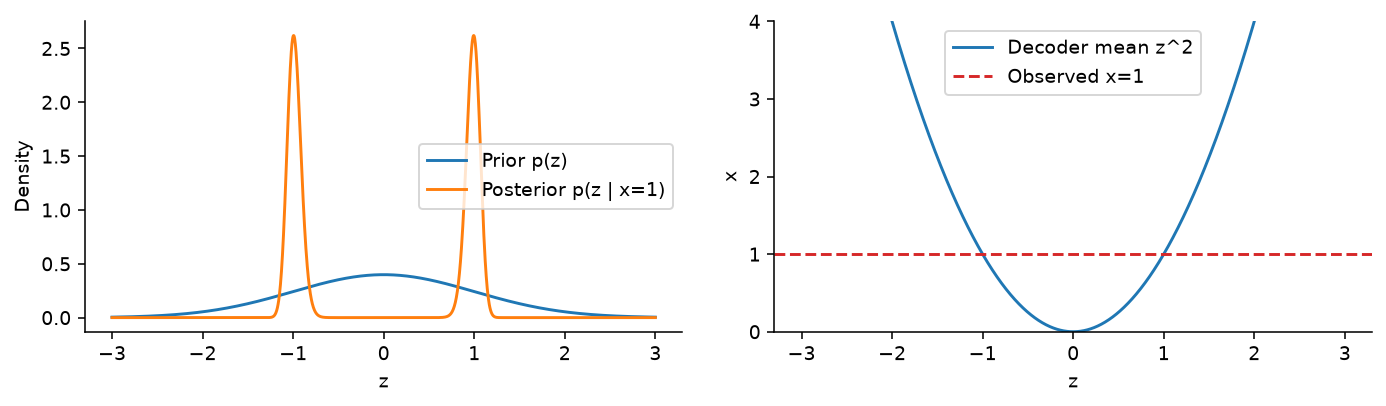

In [4]:
z_axis = np.linspace(-3, 3, 1601)
sigma_toy = 0.15
observed_x = 1.0
prior = np.exp(-0.5 * z_axis ** 2) / np.sqrt(2 * np.pi)
likelihood = np.exp(-0.5 * ((observed_x - z_axis ** 2) / sigma_toy) ** 2)
likelihood /= sigma_toy * np.sqrt(2 * np.pi)
posterior = prior * likelihood
posterior /= np.trapezoid(posterior, z_axis) if hasattr(np, "trapezoid") else np.trapz(posterior, z_axis)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(z_axis, prior, label="Prior p(z)")
axes[0].plot(z_axis, posterior, label="Posterior p(z | x=1)")
axes[0].set(xlabel="z", ylabel="Density")
axes[0].legend()
axes[1].plot(z_axis, z_axis ** 2, label="Decoder mean z^2")
axes[1].axhline(observed_x, color="tab:red", linestyle="--", label="Observed x=1")
axes[1].set(xlabel="z", ylabel="x", ylim=(0, 4))
axes[1].legend()
fig.tight_layout()
plt.show()

## 4. Вариационный автоэнкодер

<img src="https://arxiv.org/html/1906.02691v3/vae_cartoon.png" alt="VAE: encoder, stochastic latent variable and decoder" width="720">

*Схема VAE. [Kingma, Welling (2019), рис. 2.2](https://arxiv.org/html/1906.02691v3).*

- Encoder задаёт $q_\phi(z\mid x)$ — вариационную аппроксимацию точного posterior $p_\theta(z\mid x)$.
- Выбранное семейство — диагональная гауссиана; многовершинный posterior представляется приближённо.

$$q_\phi(z\mid x)=\mathcal N\left(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))\right).$$

**Репараметризация:**

$$\epsilon\sim\mathcal N(0,I),\qquad z=\mu+\exp(\ell/2)\odot\epsilon,\quad \ell=\log\sigma^2.$$

$z$ дифференцируемо зависит от $\mu,\ell$; `logvar` хранит логарифм дисперсии.

<details><summary>Целевая функция и нормировка</summary>

- Prior: $p(z)=\mathcal N(0,I)$.
- Likelihood: $p_\theta(x\mid z)=\mathcal N(g_\theta(z),\sigma_x^2 I)$, $\sigma_x=0.2$.
- На изображениях показано среднее $g_\theta(z)$; гауссовская модель допускает значения вне $[0,1]$.

$$\log p_\theta(x)\ \geq\ \underbrace{\mathbb E_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]-D_{KL}(q_\phi(z\mid x)\Vert p(z))}_{\operatorname{ELBO}(x)}.$$

$$\mathcal L_{\beta}(x)=\underbrace{\mathbb E_q\frac{\sum_{j=1}^{784}(x_j-g_\theta(z)_j)^2}{2\sigma_x^2}}_{\text{reconstruction cost}}+\beta\underbrace{\frac12\sum_{k=1}^{16}\left[\mu_k^2+\exp(\ell_k)-1-\ell_k\right]}_{D_{KL}(q\Vert\mathcal N(0,I))},\quad\ell_k=\log\sigma_k^2.$$

- $\beta=1$: отрицательный ELBO без постоянной likelihood.
- $\beta\ne1$: взвешенная цель β-VAE.
- Суммы — по координатам объекта; затем усреднение по батчу.
- Замена суммы по 784 пикселям средним увеличивает относительный вес KL в 784 раза.
- KL ограничивает каждый $q(z\mid x)$; равенство распределений и качество генерации не гарантируются.

</details>

**Теория:** [ELBO](https://fpakhurov.com/ru/notes/generative-models/vae/#variational-approximation-and-the-elbo), [репараметризация](https://fpakhurov.com/ru/notes/generative-models/vae/#the-reparameterization-trick).

VAE classes=0: 18 epochs in 6.2 s


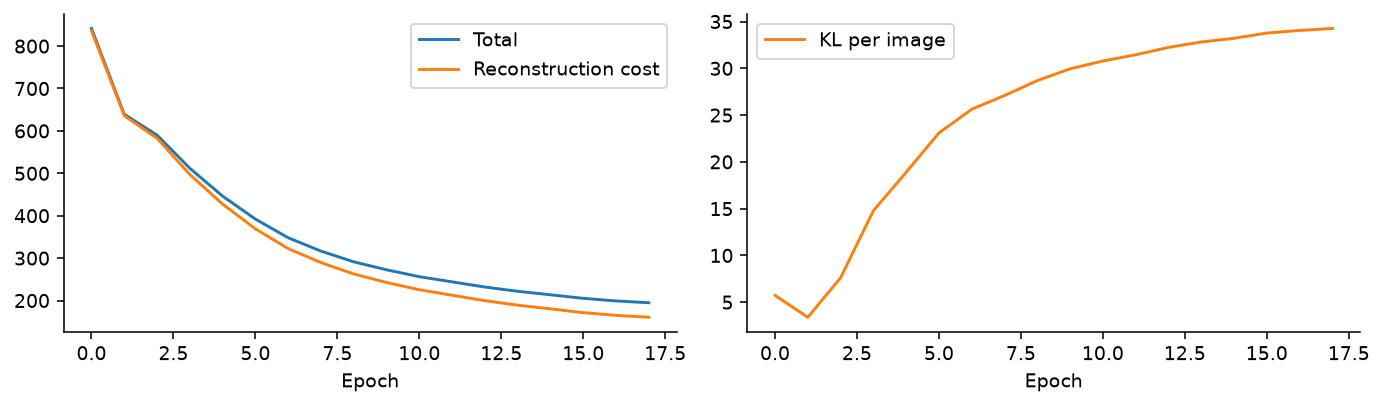

In [5]:
OBS_SIGMA = 0.2
BETA = 1.0
VAE_EPOCHS = 3 if QUICK else 18


class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, num_classes=0):
        super().__init__()
        self.latent_dim = latent_dim
        self.num_classes = num_classes
        self.encoder = nn.Sequential(nn.Linear(INPUT_DIM + num_classes, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU())
        self.mu_head = nn.Linear(256, latent_dim)
        self.logvar_head = nn.Linear(256, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim + num_classes, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, INPUT_DIM), nn.Sigmoid())

    def condition(self, values, labels=None):
        if self.num_classes == 0:
            return values
        if labels is None:
            raise ValueError("Conditional VAE requires class labels")
        one_hot = F.one_hot(labels, self.num_classes).to(values.dtype)
        return torch.cat([values, one_hot], dim=1)

    def encode(self, x, labels=None):
        hidden = self.encoder(self.condition(x, labels))
        return self.mu_head(hidden), self.logvar_head(hidden).clamp(-10, 10)

    def decode(self, z, labels=None):
        return self.decoder(self.condition(z, labels))

    def forward(self, x, labels=None):
        mu, logvar = self.encode(x, labels)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decode(z, labels), mu, logvar


def vae_loss(reconstruction, x, mu, logvar, beta=1.0):
    reconstruction_cost = ((x - reconstruction).square().sum(dim=1) / (2 * OBS_SIGMA ** 2)).mean()
    kl = 0.5 * (mu.square() + logvar.exp() - 1 - logvar).sum(dim=1).mean()
    return reconstruction_cost + beta * kl, reconstruction_cost, kl


def train_vae(model, epochs, beta=1.0):
    optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
    history = []
    started = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        total = np.zeros(3)
        count = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            reconstruction, mu, logvar = model(xb, yb if model.num_classes else None)
            loss, reconstruction_cost, kl = vae_loss(reconstruction, xb, mu, logvar, beta)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            total += np.array([loss.item(), reconstruction_cost.item(), kl.item()]) * len(xb)
            count += len(xb)
        history.append(total / count)
    print(f"VAE classes={model.num_classes}: {epochs} epochs in {time.perf_counter() - started:.1f} s")
    model.eval()
    return np.asarray(history)


vae = VAE().to(device)
vae_history = train_vae(vae, VAE_EPOCHS, beta=BETA)
assert np.isfinite(vae_history).all(), "Non-finite VAE loss"
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(vae_history[:, 0], label="Total")
axes[0].plot(vae_history[:, 1], label="Reconstruction cost")
axes[1].plot(vae_history[:, 2], label="KL per image", color="tab:orange")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.legend()
fig.tight_layout()
plt.show()

## 5. Реконструкция, генерация, интерполяция

- **Реконструкция:** $x\to\mu_\phi(x)\to g_\theta(\mu_\phi(x))$; используется среднее приблизительного posterior.
- **Генерация:** $z\sim p(z)\to g_\theta(z)$; encoder не требуется.
- **Интерполяция:** линейный путь между кодами; принадлежность типичной области prior не гарантирована.

**Практика:** сравнить реконструкции и генерации; повторить генерацию с новым шумом.

**Теория:** [VAE](https://fpakhurov.com/ru/notes/generative-models/vae/).

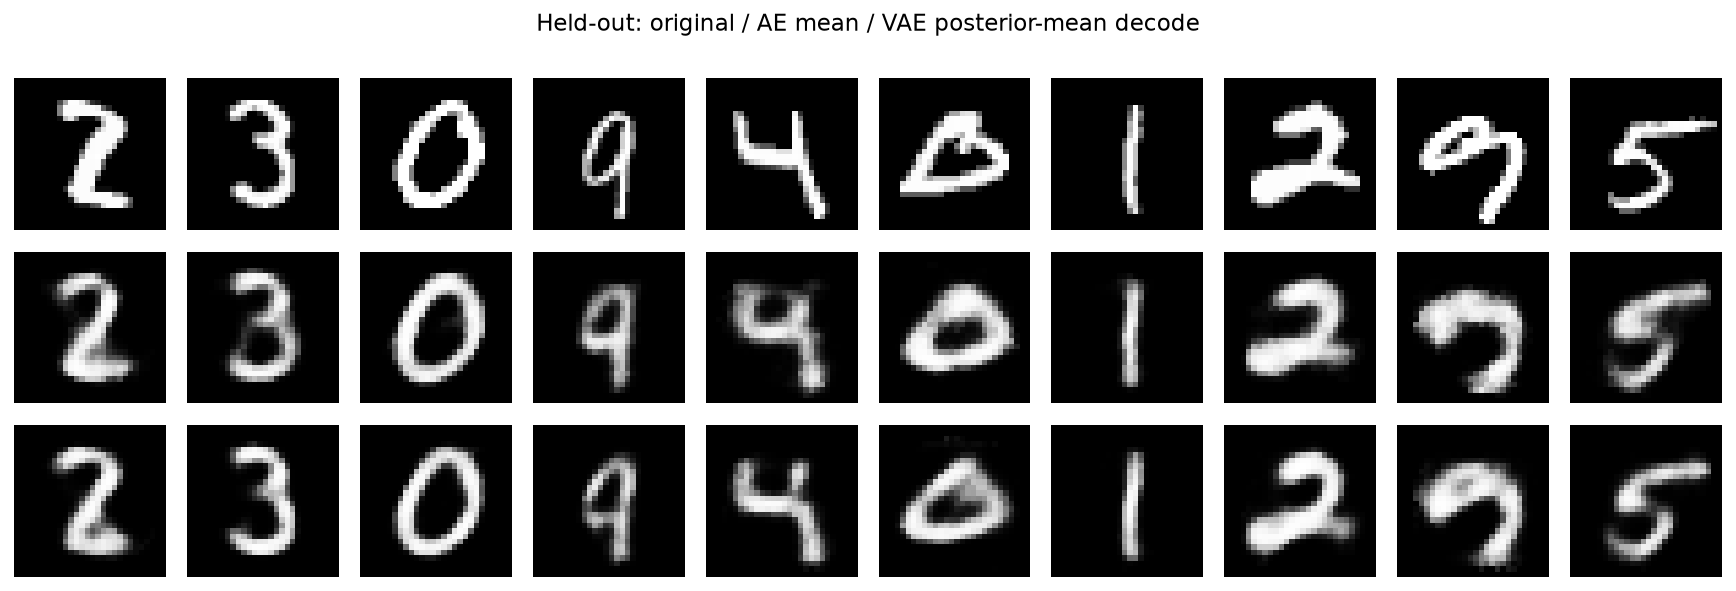

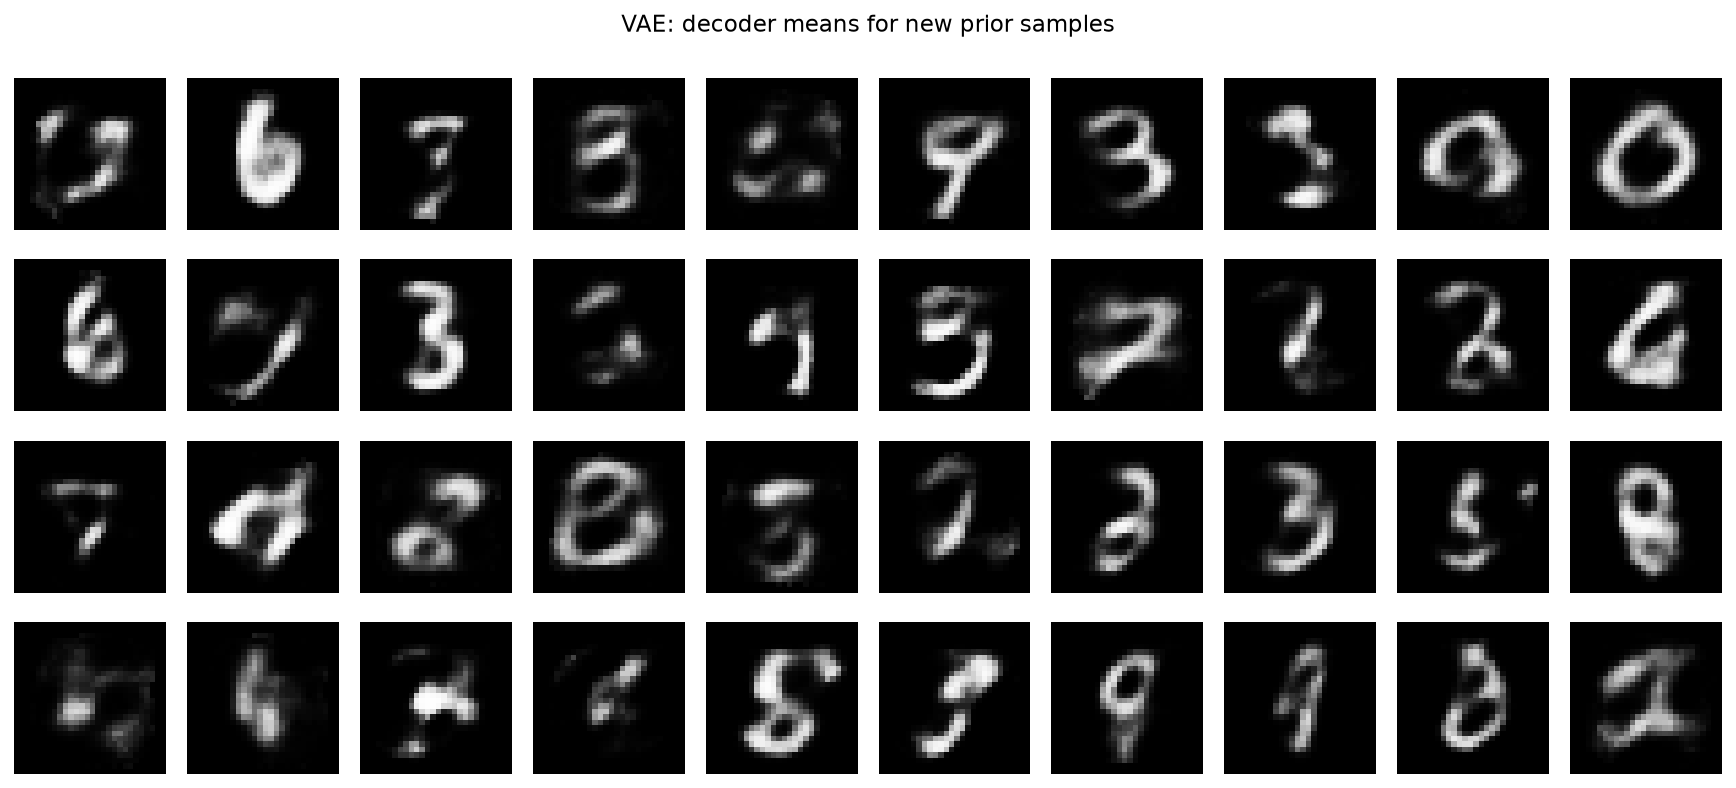

Held-out per-pixel MSE: AE=0.0211; VAE=0.0154


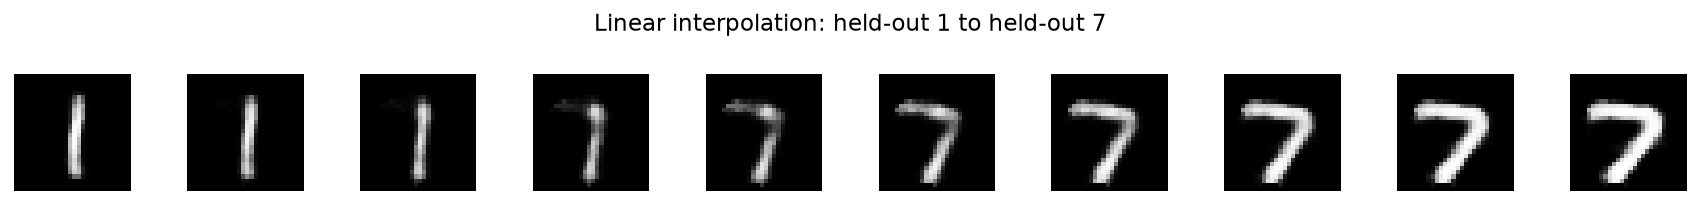

In [6]:
with torch.no_grad():
    test_mu, test_logvar = vae.encode(x_test.to(device))
    vae_reconstruction = vae.decode(test_mu).cpu()
    vae_samples = vae.decode(torch.randn(40, LATENT_DIM, device=device)).cpu()
    ae_test_mse = F.mse_loss(ae(x_test.to(device)), x_test.to(device)).item()
    vae_test_mse = F.mse_loss(vae_reconstruction, x_test).item()
image_grid(torch.cat([x_test[:10], ae_reconstruction[:10], vae_reconstruction[:10]]),
           "Held-out: original / AE mean / VAE posterior-mean decode")
image_grid(vae_samples, "VAE: decoder means for new prior samples")
print(f"Held-out per-pixel MSE: AE={ae_test_mse:.4f}; VAE={vae_test_mse:.4f}")

index_a = int(np.flatnonzero(y_test_np == 1)[0])
index_b = int(np.flatnonzero(y_test_np == 7)[0])
with torch.no_grad():
    weights = torch.linspace(0, 1, 10, device=device).unsqueeze(1)
    latent_path = (1 - weights) * test_mu[index_a] + weights * test_mu[index_b]
    interpolation = vae.decode(latent_path).cpu()
image_grid(interpolation, "Linear interpolation: held-out 1 to held-out 7")

- AE и VAE различаются целями, архитектурами, инициализациями и числом эпох: сравнение учебное.
- MSE реконструкции не оценивает качество генерации.
- Здесь пиксели в $[0,1]$; во втором семинаре — $[-1,1]$. Для одинаковых ошибок MSE второй шкалы больше в 4 раза.
- Размытие зависит от архитектуры, likelihood, данных и ограничений posterior.

### Дополнительно: моменты приблизительного posterior

**Эксперимент:** получить 4000 выборок $z\sim q(z\mid x)$; сопоставить эмпирические среднее/дисперсию с $\mu,\sigma^2$; декодировать десять кодов.

Posterior coordinate check: predicted mean, empirical mean, predicted variance, empirical variance
[[-1.825 -1.825  0.04   0.04 ]
 [-1.751 -1.752  0.013  0.013]
 [-0.644 -0.647  0.014  0.015]
 [ 2.449  2.45   0.018  0.018]
 [ 1.651  1.652  0.029  0.029]
 [ 2.257  2.256  0.009  0.009]
 [ 0.292  0.291  0.022  0.022]
 [ 0.151  0.152  0.013  0.013]
 [ 1.311  1.31   0.066  0.066]
 [-0.102 -0.101  0.138  0.139]
 [ 0.941  0.942  0.005  0.005]
 [-1.294 -1.293  0.015  0.014]
 [-0.031 -0.035  0.023  0.023]
 [-0.277 -0.277  0.004  0.004]
 [-0.834 -0.833  0.013  0.013]
 [-1.7   -1.698  0.025  0.024]]


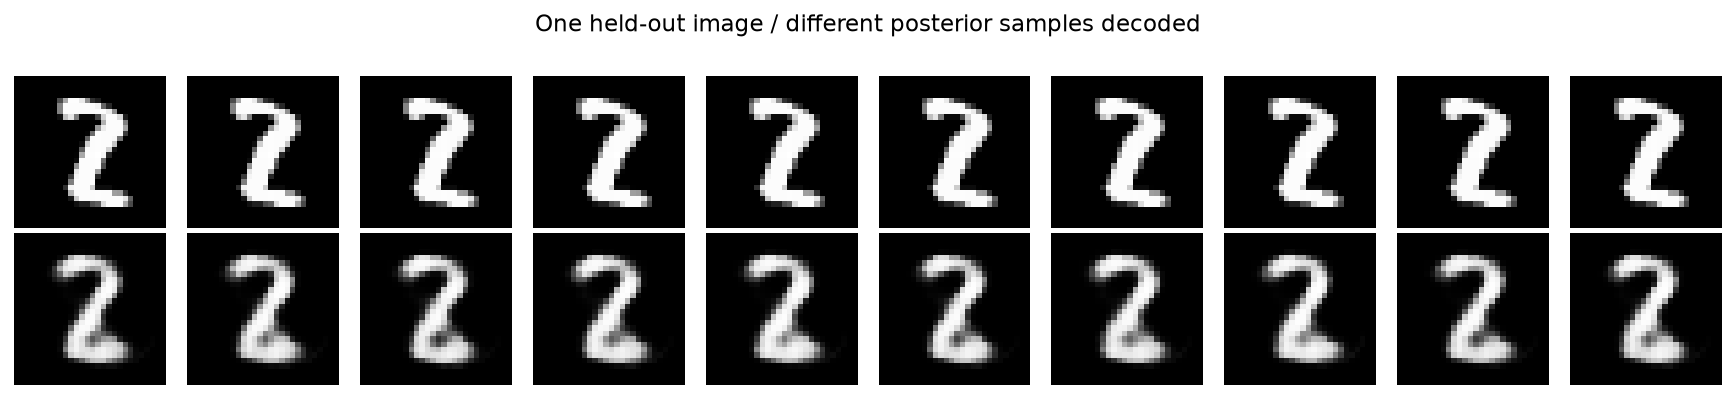

In [7]:
with torch.no_grad():
    mu_one = test_mu[0]
    var_one = test_logvar[0].exp()
    z_posterior = mu_one + var_one.sqrt() * torch.randn(4000, LATENT_DIM, device=device)
    print("Posterior coordinate check: predicted mean, empirical mean, predicted variance, empirical variance")
    check = torch.stack([mu_one, z_posterior.mean(0), var_one, z_posterior.var(0, unbiased=False)], dim=1)
    print(np.round(check.cpu().numpy(), 3))
    posterior_images = vae.decode(z_posterior[:10]).cpu()
image_grid(torch.cat([x_test[0:1].repeat(10, 1), posterior_images]),
           "One held-out image / different posterior samples decoded")

- Разброс $q(z\mid x)$ характеризует выбранную аппроксимацию скрытого кода.
- Калибровка неопределённости этим экспериментом не проверяется.

<details><summary>Дополнительно: влияние β</summary>

- Сравнить отдельные VAE с $\beta=0.1$ и $\beta=4$: реконструкции, KL, генерации.
- Для контролируемого сравнения пересоздавать модель, optimizer и DataLoader с одинаковым seed; `torch.manual_seed` не сбрасывает генератор существующего DataLoader.
- Большой β усиливает KL; возможна потеря информации в коде. При KL=0 выполняется $q(z\mid x)=p(z)$.
- Меньший β ослабляет согласование с prior; качество проверяется экспериментально.

</details>

## 6. Дополнительно: восстановление повреждений

- Закрыть фрагмент test-изображения; применить VAE без дообучения.
- Сравнить MSE пропуска с заполнением нулями.
- Ограничение: модель обучалась на чистых входах без маски; $p(x_{\rm missing}\mid x_{\rm observed})$ не вычисляется.
- Специализированные варианты: denoising AE, условные модели, диффузионное восстановление.

Missing-region MSE: zero-fill=0.3507; VAE baseline=0.2641


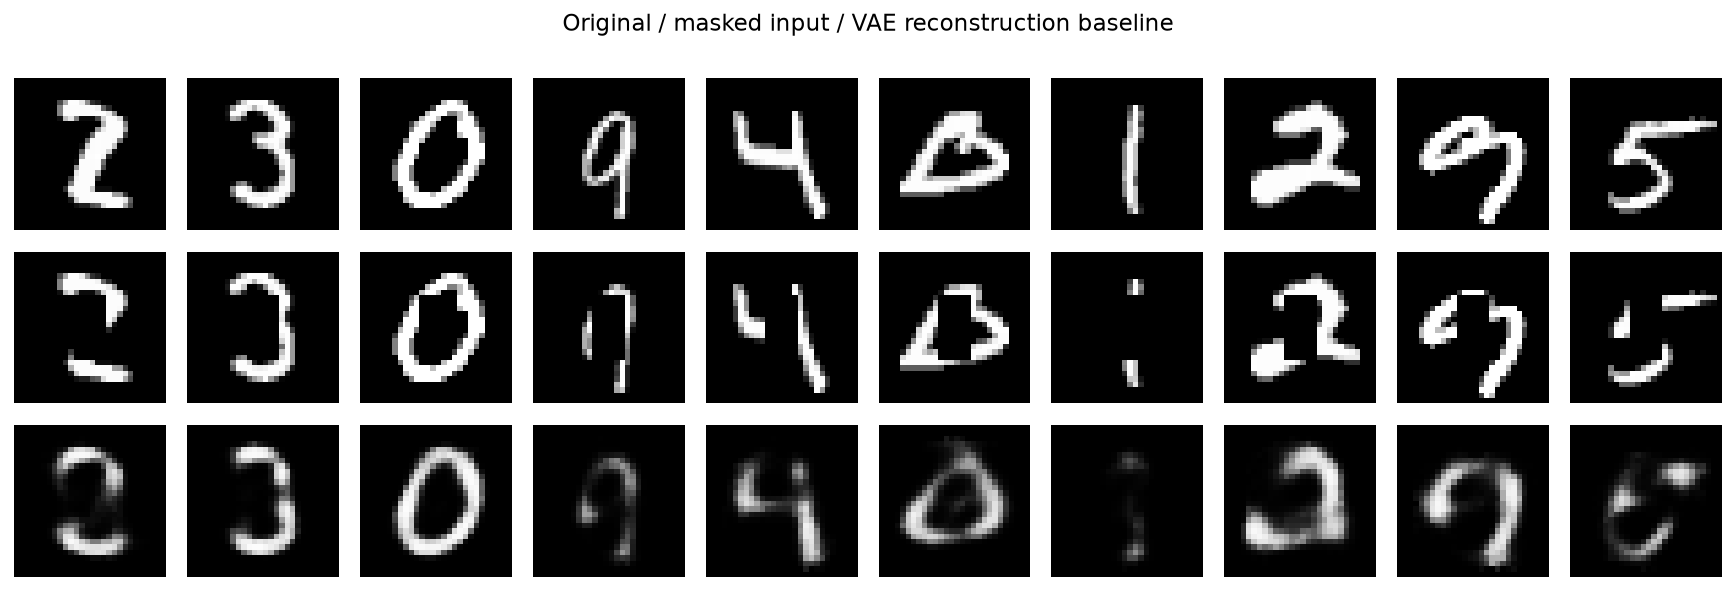

In [8]:
clean = x_test[:10].clone()
mask = torch.ones(IMAGE_SIZE, IMAGE_SIZE)
mask[8:20, 11:17] = 0
corrupted = clean * mask.flatten()
with torch.no_grad():
    corrupted_mu, _ = vae.encode(corrupted.to(device))
    restored = vae.decode(corrupted_mu).cpu()
missing = (1 - mask.flatten()).bool()
print(f"Missing-region MSE: zero-fill={F.mse_loss(corrupted[:, missing], clean[:, missing]):.4f}; VAE baseline={F.mse_loss(restored[:, missing], clean[:, missing]):.4f}")
image_grid(torch.cat([clean, corrupted, restored]), "Original / masked input / VAE reconstruction baseline")

## 7. Генеративно-состязательная сеть

В VAE обучение определяется выбранными likelihood и вариационным приближением. Рассмотрим другой критерий: генератор получает градиент от обучаемого дискриминатора. Сравним характер генераций и разнообразие; универсального преимущества одного семейства здесь не устанавливаем.

<img src="https://arxiv.org/html/1511.06434v2/lsun_bedrooms_generator.png" alt="DCGAN generator: transposed convolutions from latent vector to image" width="720">

*Генератор DCGAN. [Radford, Metz, Chintala (2016), рис. 1](https://arxiv.org/html/1511.06434v2). В практикуме используется компактный свёрточный генератор 7→14→28.*

- $G_\theta$: шум $[B,64]$ → изображение $[B,784]$; выход `Tanh` преобразуется в $[0,1]$.
- $D_\psi$: изображение $[B,784]$ → logit $[B,1]$.
- $s(x)=\operatorname{sigmoid}(D(x))$; `BCEWithLogitsLoss` объединяет сигмоиду и cross-entropy.

$$\min_\psi\ \mathcal L_D=-\mathbb E_{x\sim p_{data}}[0.9\log s(x)+0.1\log(1-s(x))]-\mathbb E_{z\sim p(z)}\log(1-s(G(z))).$$
$$\min_\theta\ \mathcal L_G=-\mathbb E_{z\sim p(z)}\log s(G(z)).$$

**Обновления:**

1. $D$: реальные данные и `G(z).detach()`; генератор не обновляется.
2. $G$: `D(G(z))` без `detach`; параметры $D$ заморожены, градиент по входу сохраняется.

- Для $G$ используется non-saturating loss.
- Значение loss, включая 0.693, не доказывает качество.
- Дискриминатор обучен относительно текущего генератора; универсальность детектора синтетики не предполагается.

**Теория:** [Цель генератора](https://fpakhurov.com/ru/notes/generative-models/gans/#which-generator-loss-is-used-in-practice), [WGAN](https://fpakhurov.com/ru/notes/generative-models/wgan/).


- Компактная DCGAN-архитектура: свёртки, BatchNorm и обучаемое увеличение пространственного разрешения.
- Метки реальных примеров сглажены до 0.9; шаг дискриминатора использует меньшую скорость обучения.

GAN: 2500 steps in 61.7 s


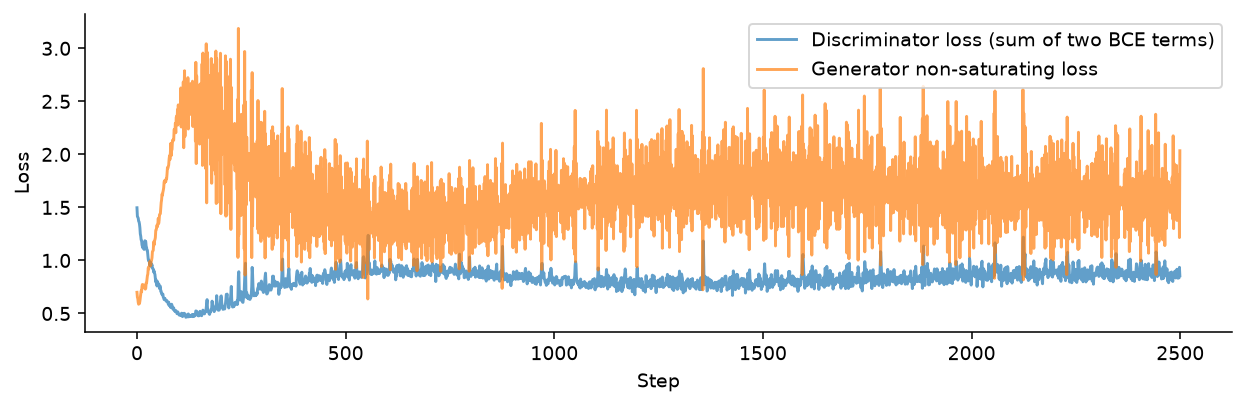

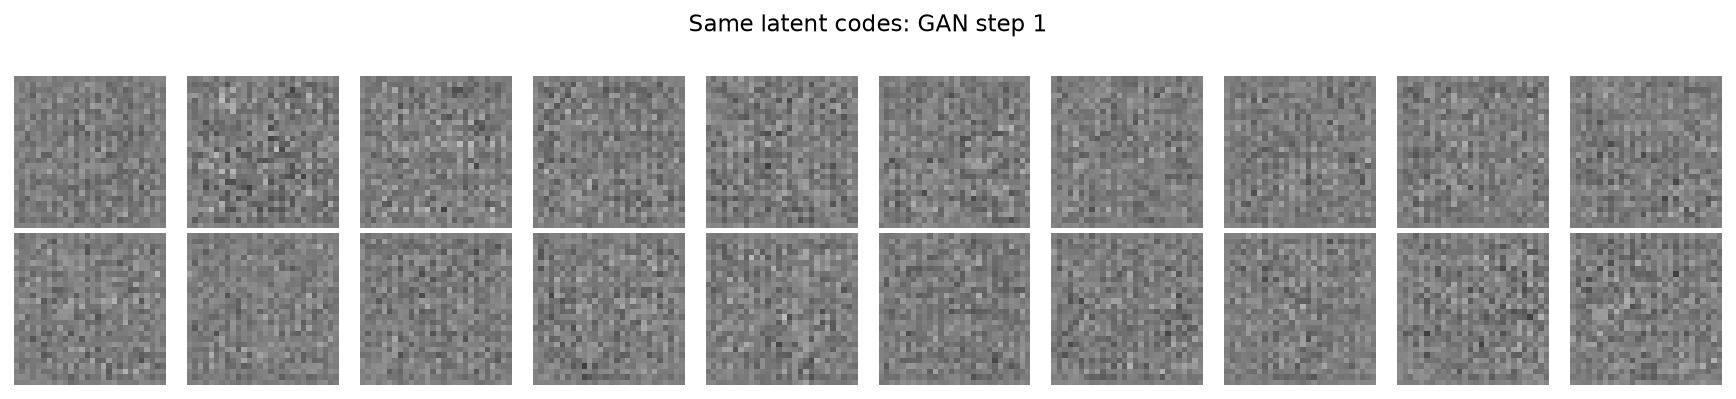

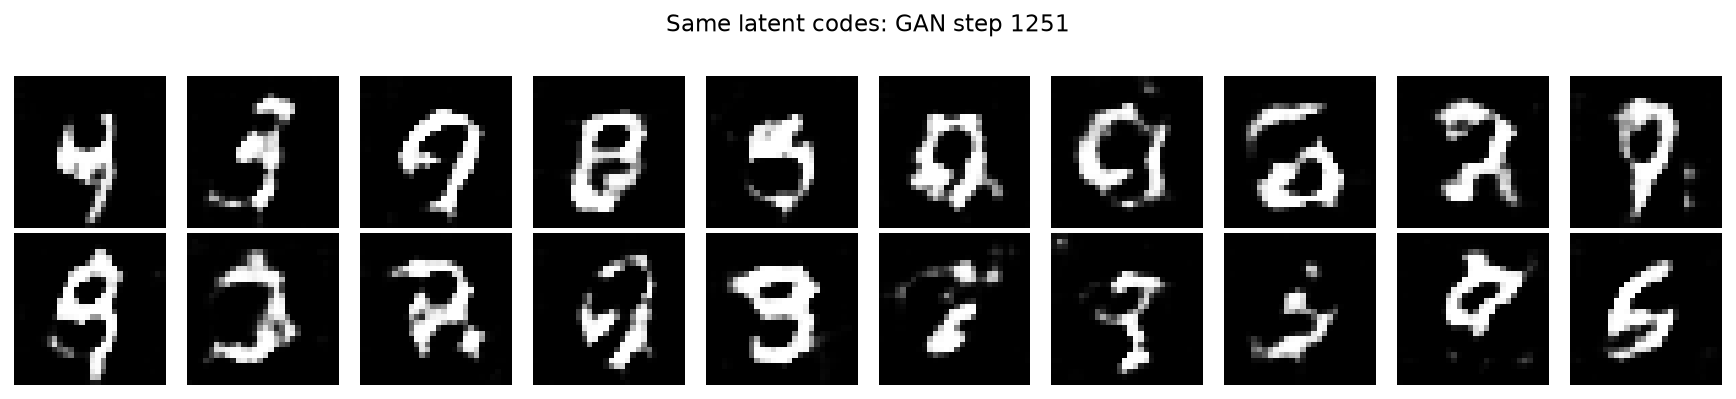

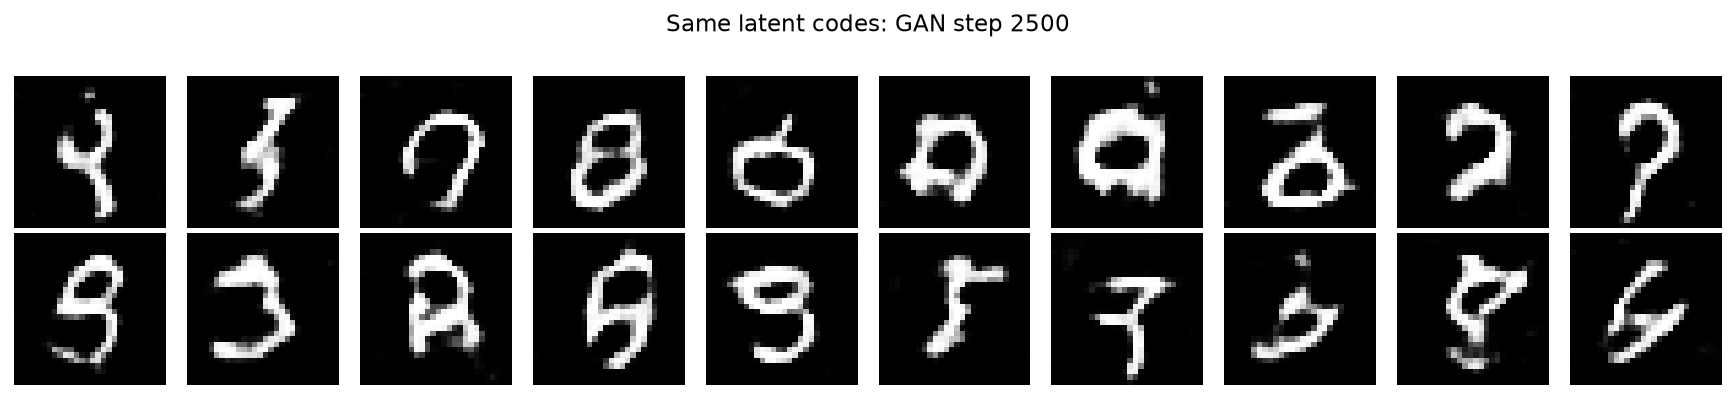

In [9]:
GAN_Z_DIM = 64
GAN_STEPS = 50 if QUICK else 2500


class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(GAN_Z_DIM, 64 * 7 * 7), nn.Unflatten(1, (64, 7, 7)), nn.BatchNorm2d(64), nn.ReLU(), nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.BatchNorm2d(32), nn.ReLU(), nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Tanh())
    def forward(self, z):
        return ((self.net(z) + 1) / 2).flatten(1)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Unflatten(1, (1, 28, 28)), nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2), nn.Conv2d(32, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.LeakyReLU(0.2), nn.Flatten(), nn.Dropout(0.2), nn.Linear(64 * 7 * 7, 1))
    def forward(self, x):
        return self.net(x * 2 - 1)

def initialize_gan(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)

generator = Generator().to(device).apply(initialize_gan)
discriminator = Discriminator().to(device).apply(initialize_gan)
g_optimizer = torch.optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(discriminator.parameters(), lr=1e-4, betas=(0.5, 0.999))
bce_logits = nn.BCEWithLogitsLoss()
fixed_noise = torch.randn(30, GAN_Z_DIM, device=device)
train_on_device = x_train.to(device)
gan_history = []
gan_snapshots = {}
started = time.perf_counter()
for step in range(GAN_STEPS):
    indices = torch.randint(len(train_on_device), (128,), device=device)
    real = train_on_device[indices]
    noise = torch.randn(len(real), GAN_Z_DIM, device=device)
    fake = generator(noise)

    for parameter in discriminator.parameters():
        parameter.requires_grad_(True)
    d_optimizer.zero_grad(set_to_none=True)
    real_logits = discriminator(real)
    fake_logits = discriminator(fake.detach())
    d_loss = bce_logits(real_logits, torch.full_like(real_logits, 0.9)) + bce_logits(fake_logits, torch.zeros_like(fake_logits))
    d_loss.backward()
    d_optimizer.step()

    for parameter in discriminator.parameters():
        parameter.requires_grad_(False)
    g_optimizer.zero_grad(set_to_none=True)
    fake_logits_for_g = discriminator(fake)
    g_loss = bce_logits(fake_logits_for_g, torch.ones_like(fake_logits_for_g))
    g_loss.backward()
    g_optimizer.step()
    gan_history.append((d_loss.item(), g_loss.item()))
    if step in {0, GAN_STEPS // 2, GAN_STEPS - 1}:
        with torch.no_grad():
            gan_snapshots[step + 1] = generator(fixed_noise).cpu()
for parameter in discriminator.parameters():
    parameter.requires_grad_(True)
generator.eval()
discriminator.eval()
gan_history = np.asarray(gan_history)
assert np.isfinite(gan_history).all(), "Non-finite GAN loss"
print(f"GAN: {GAN_STEPS} steps in {time.perf_counter() - started:.1f} s")
fig, axis = plt.subplots(figsize=(9, 3))
axis.plot(gan_history[:, 0], alpha=0.7, label="Discriminator loss (sum of two BCE terms)")
axis.plot(gan_history[:, 1], alpha=0.7, label="Generator non-saturating loss")
axis.set(xlabel="Step", ylabel="Loss")
axis.legend()
fig.tight_layout()
plt.show()
for step, images in gan_snapshots.items():
    image_grid(images[:20], f"Same latent codes: GAN step {step}")

### Анализ обучения

- Сравнить изображения при фиксированных $z$: структура, разнообразие, артефакты.
- Loss GAN зависит от текущего дискриминатора; численно с VAE-loss не сопоставляется.
- В реализации $\mathcal L_D$ — сумма двух BCE; $\mathcal L_G$ — одна BCE.

## 8. Дополнительно: диагностика разнообразия

- Классификатор обучается только на train.
- Сопоставляются классы реальных test-данных и генераций.
- Повтор одного изображения 400 раз — искусственный пример коллапса.
- Гистограмма — эвристика; ошибки классификатора могут скрывать артефакты. Это не FID.

**Теория:** [Precision и recall генеративных моделей](https://fpakhurov.com/ru/notes/generative-models/precision-recall/).

Probe held-out accuracy: 0.907


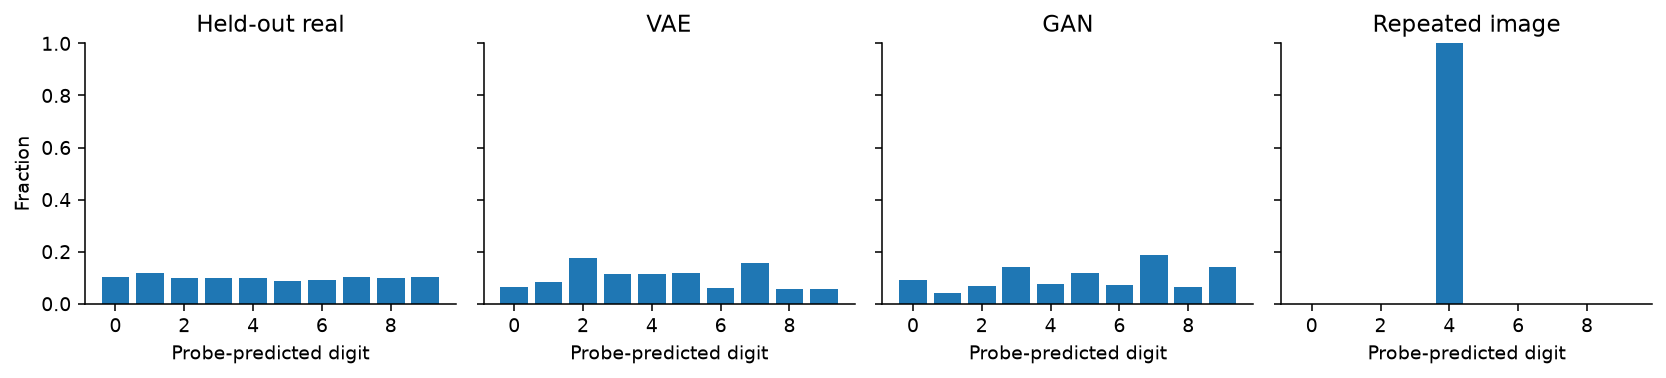

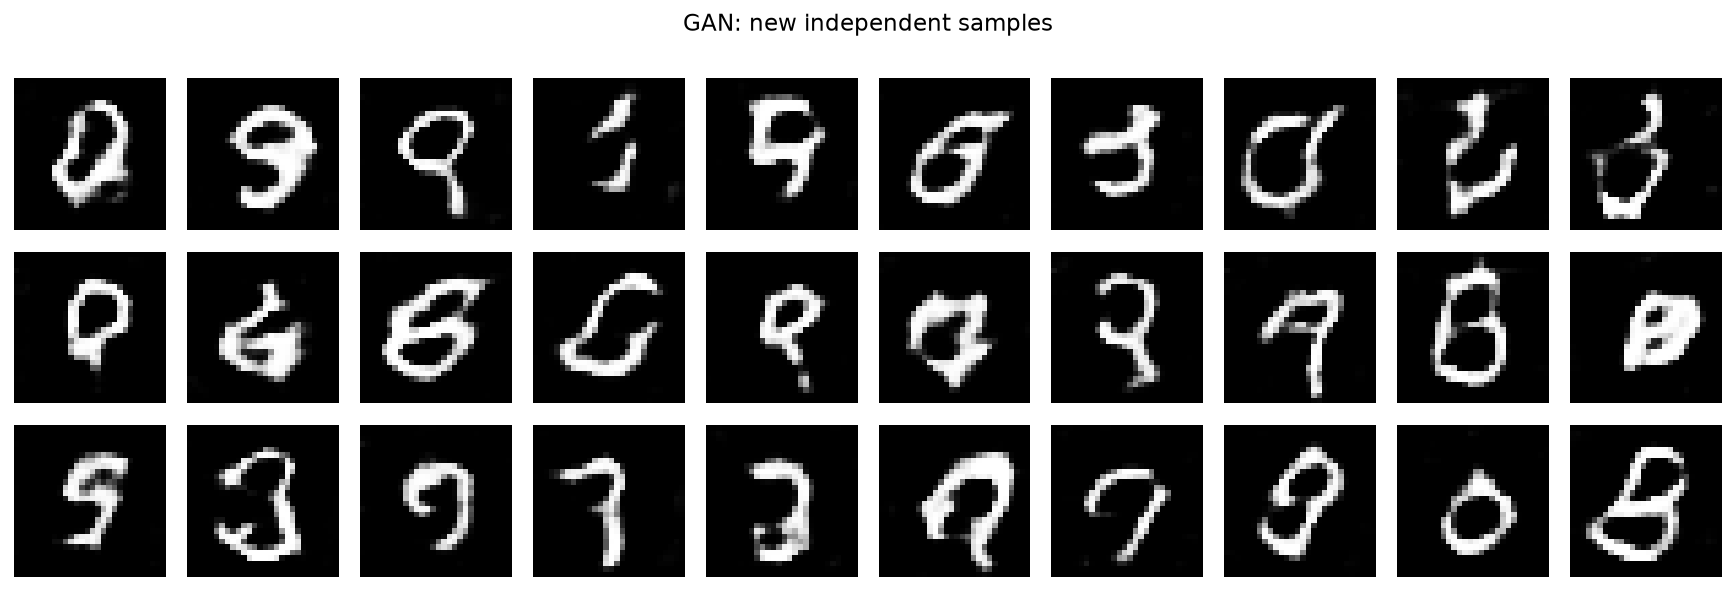

In [10]:
probe = LogisticRegression(max_iter=300, random_state=SEED)
probe.fit(x_train_np, y_train_np)
print(f"Probe held-out accuracy: {probe.score(x_test_np, y_test_np):.3f}")
with torch.no_grad():
    generated_gan = generator(torch.randn(400, GAN_Z_DIM, device=device)).cpu().numpy()
    generated_vae = vae.decode(torch.randn(400, LATENT_DIM, device=device)).cpu().numpy()
collapsed_baseline = np.repeat(generated_gan[:1], 400, axis=0)
comparison_sets = {
    "Held-out real": x_test_np,
    "VAE": generated_vae,
    "GAN": generated_gan,
    "Repeated image": collapsed_baseline,
}
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
for axis, (name, images) in zip(axes, comparison_sets.items()):
    predictions = probe.predict(images)
    proportions = np.bincount(predictions, minlength=10) / len(predictions)
    axis.bar(np.arange(10), proportions)
    axis.set(title=name, xlabel="Probe-predicted digit", xticks=np.arange(0, 10, 2), ylim=(0, 1))
axes[0].set_ylabel("Fraction")
fig.tight_layout()
plt.show()
image_grid(torch.tensor(generated_gan[:30]), "GAN: new independent samples")

<details><summary>Задание: ограничения классификатора</summary>

Сопоставить визуальное разнообразие с предсказаниями классов. Равномерная гистограмма возможна у артефактов. Польза синтетики проверяется downstream-метрикой на независимых реальных данных.

</details>

## 9. Условные варианты: разделение классов

**Условие:** класс $y\in\{0,\ldots,9\}$.

$$p_\theta(x\mid y)=\int p_\theta(x\mid z,y)p(z)\,dz,\qquad q_\phi(z\mid x,y).$$

- Обучение: $y$ передаётся encoder и decoder через one-hot.
- Генерация: $y$, $z\sim\mathcal N(0,I)$, decoder.
- Prior независим от класса.
- В опыте cVAE используется β=4: усиленный KL-штраф уменьшает выгодность кодирования класса только в $z$. Это модифицированная β-VAE-цель; отрицательная ELBO соответствует β=1.
- После занятия: сравнить β=1 и β=4 по управлению классом и деталям изображения; это требует повторного обучения.
- Диагностика: соответствие запрошенного класса предсказанию классификатора.

**Теория:** [Варианты VAE](https://fpakhurov.com/ru/notes/generative-models/vae-variants/).


- Без условия $p(x)=\sum_y p(y)p(x\mid y)$ смешивает классы; с условием моделируется $p(x\mid y)$.
- Метка задаёт целевой класс; $z$ допускает разнообразие внутри класса. Полное отделение почерка от класса не гарантировано.
- Для скалярного признака $U$: $\operatorname{Var}(U)=\mathbb E_Y[\operatorname{Var}(U\mid Y)]+\operatorname{Var}_Y(\mathbb E[U\mid Y])$.
- Первое слагаемое — внутриклассовая вариативность; второе — межклассовая. Фиксация $y$ устраняет смешение классов, сохраняя вариативность внутри выбранного класса.
- Сравнение ниже: одинаковый $z$ в каждом столбце, разные метки по строкам.

VAE classes=10: 50 epochs in 17.7 s


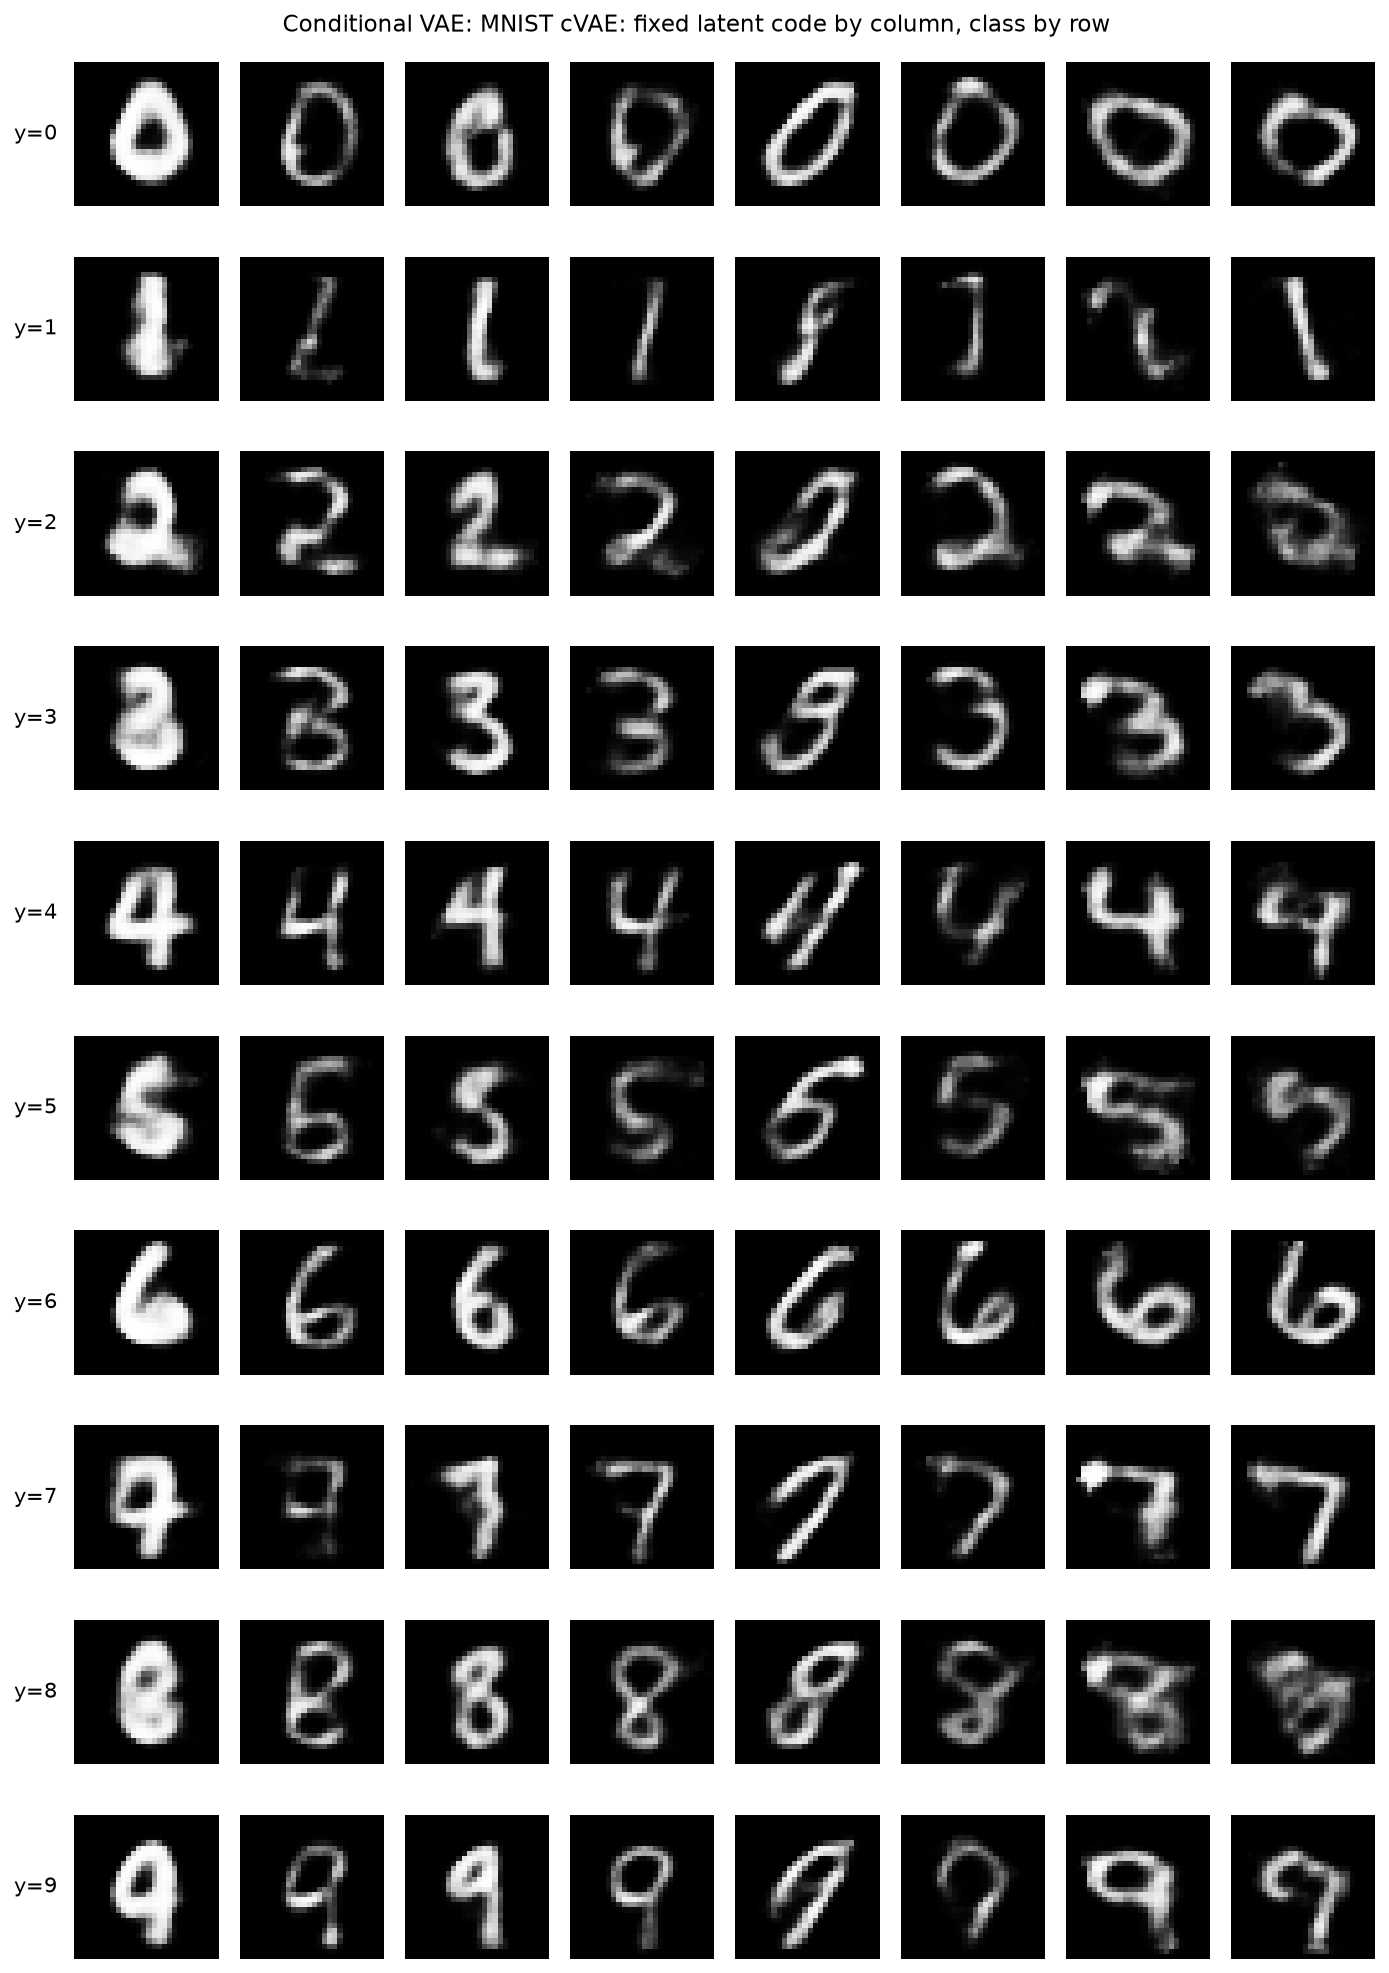

Probe agreement with requested class: 0.938
Probe agreement is a classroom diagnostic, not a calibrated quality metric.


In [11]:
CVAE_EPOCHS = 3 if QUICK else 50
CVAE_BETA = 4.0
torch.manual_seed(SEED)
cvae = VAE(num_classes=10).to(device)
cvae_history = train_vae(cvae, CVAE_EPOCHS, beta=CVAE_BETA)
with torch.no_grad():
    requested_classes = torch.arange(10, device=device).repeat_interleave(8)
    conditional_images = cvae.decode(
        torch.randn(8, LATENT_DIM, device=device).repeat(10, 1), requested_classes
    ).cpu()
image_grid(conditional_images, "Conditional VAE: MNIST cVAE: fixed latent code by column, class by row", columns=8, row_labels=range(10))
conditional_predictions = probe.predict(conditional_images.numpy())
print(f"Probe agreement with requested class: {(conditional_predictions == requested_classes.cpu().numpy()).mean():.3f}")
print("Probe agreement is a classroom diagnostic, not a calibrated quality metric.")

### Условный GAN

- Генератор: $G(z,y)$; дискриминатор: $D(x,y)$.
- Условие передаётся обеим сетям. Проекционный дискриминатор сопоставляет признаки изображения с embedding класса.
- Эксперимент: фиксировать шум по столбцам, изменять метку по строкам; сравнить с безусловным GAN.
- Условие уменьшает смешение классов; ошибки, недостаток разнообразия и коллапс остаются возможными.

**Теория:** [Условные генеративные модели](https://fpakhurov.com/ru/notes/generative-models/gans/).

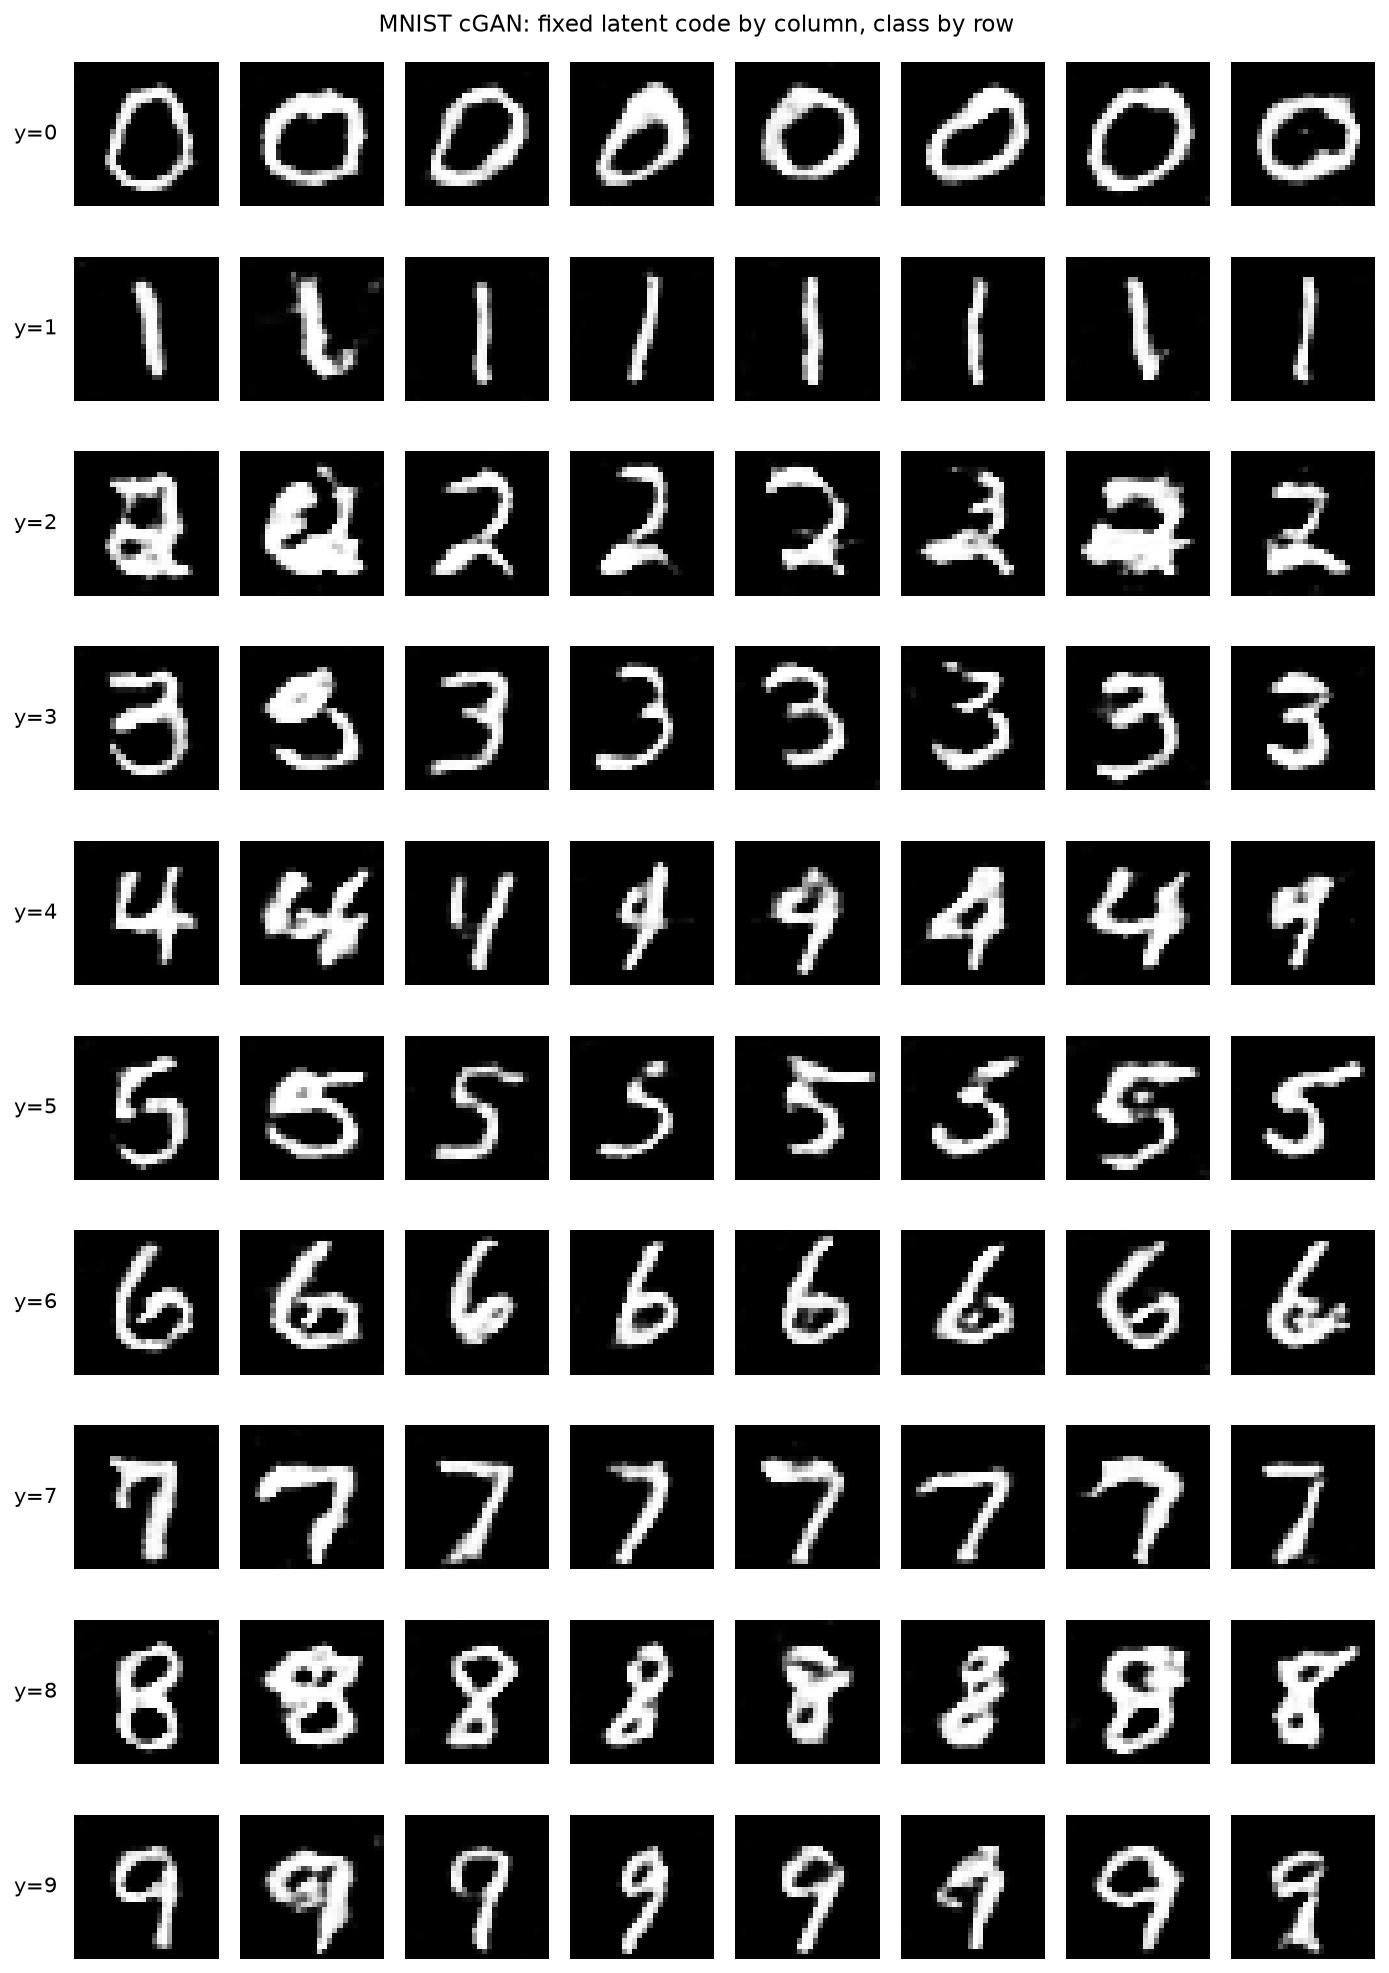

cGAN: 3000 steps in 73.0 s; probe class agreement: 0.963
Probe agreement is a diagnostic, not a complete generation-quality measure.


In [12]:
class ConditionalGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(10, 32)
        self.net = nn.Sequential(nn.Linear(GAN_Z_DIM + 32, 64 * 7 * 7), nn.Unflatten(1, (64, 7, 7)), nn.BatchNorm2d(64), nn.ReLU(), nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.BatchNorm2d(32), nn.ReLU(), nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Tanh())
    def forward(self, z, labels):
        return ((self.net(torch.cat([z, self.embedding(labels)], dim=1)) + 1) / 2).flatten(1)

class ConditionalDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Unflatten(1, (1, 28, 28)), nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2), nn.Conv2d(32, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.LeakyReLU(0.2), nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.LeakyReLU(0.2))
        self.output = nn.Linear(128, 1)
        self.embedding = nn.Embedding(10, 128)
    def forward(self, x, labels):
        h = self.features(x * 2 - 1)
        return self.output(h) + (h * self.embedding(labels)).sum(dim=1, keepdim=True) / (128 ** 0.5)

cgan = ConditionalGenerator().to(device).apply(initialize_gan)
cdisc = ConditionalDiscriminator().to(device).apply(initialize_gan)
cg_opt = torch.optim.Adam(cgan.parameters(), lr=2e-4, betas=(0.5, 0.999))
cd_opt = torch.optim.Adam(cdisc.parameters(), lr=1e-4, betas=(0.5, 0.999))
cgan_steps = 50 if QUICK else 3000
train_labels_device = y_train.to(device)
start = time.perf_counter()
for step in range(cgan_steps):
    idx = torch.randint(len(train_on_device), (128,), device=device)
    real, labels = train_on_device[idx], train_labels_device[idx]
    fake = cgan(torch.randn(len(idx), GAN_Z_DIM, device=device), labels)
    cdisc.requires_grad_(True)
    cd_opt.zero_grad(set_to_none=True)
    real_logits, fake_logits = cdisc(real, labels), cdisc(fake.detach(), labels)
    cd_loss = bce_logits(real_logits, torch.full_like(real_logits, 0.9)) + bce_logits(fake_logits, torch.zeros_like(fake_logits))
    cd_loss.backward(); cd_opt.step()
    cdisc.requires_grad_(False)
    cg_opt.zero_grad(set_to_none=True)
    logits = cdisc(fake, labels)
    cg_loss = bce_logits(logits, torch.ones_like(logits))
    cg_loss.backward(); cg_opt.step()
cgan.eval()
cdisc.eval()
with torch.no_grad():
    class_grid = torch.arange(10, device=device).repeat_interleave(8)
    repeated_z = torch.randn(8, GAN_Z_DIM, device=device).repeat(10, 1)
    cgan_images = cgan(repeated_z, class_grid).cpu()
image_grid(cgan_images, "MNIST cGAN: fixed latent code by column, class by row", columns=8, row_labels=range(10))
cgan_agreement = float((probe.predict(cgan_images.numpy()) == class_grid.cpu().numpy()).mean())
print(f"cGAN: {cgan_steps} steps in {time.perf_counter()-start:.1f} s; probe class agreement: {cgan_agreement:.3f}")
print("Probe agreement is a diagnostic, not a complete generation-quality measure.")

### Практика 1. Метка класса и случайный код — 8 минут

- Выполнить «Выполнить все» один раз; дождаться обучения cVAE/cGAN. Ниже выполняется только генерация.
- **Гипотеза:** при фиксированном `LATENT_SEED` смена `TARGET_CLASS` меняет класс изображения.
- **Действие:** выбрать 3, затем 8; сохранить seed. После этого изменить только seed.
- **Результат:** сопоставить управление классом, различия начертания и ошибки моделей. Одинаковый seed не означает одинаковое латентное пространство двух моделей.
- Обучающие ячейки и перебор β повторно на занятии не запускаются.

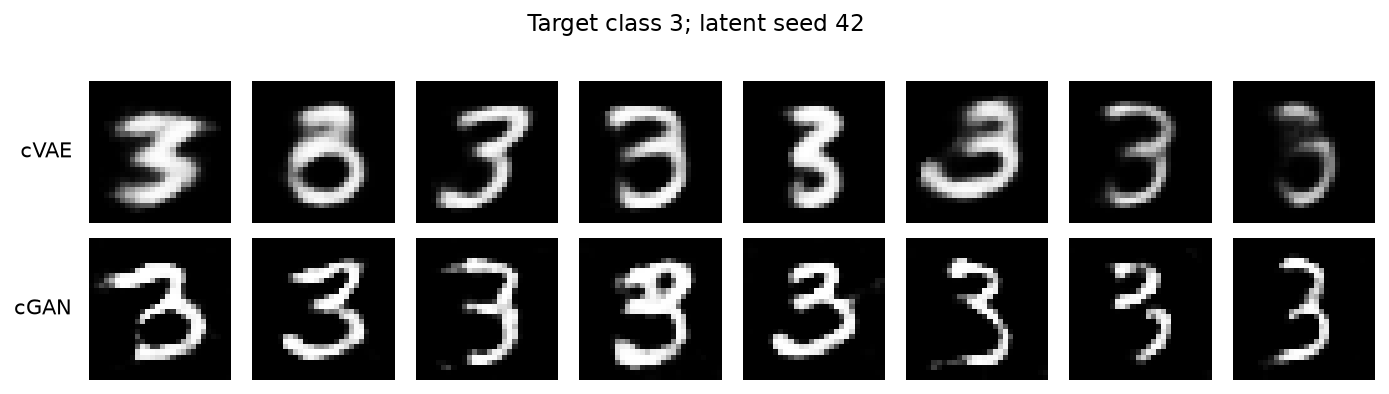

Inference only; no training performed.


In [13]:
#@title Practice 1: change the class without retraining
TARGET_CLASS = 3 #@param {type:"slider", min:0, max:9, step:1}
LATENT_SEED = 42 #@param {type:"integer"}

local_rng = torch.Generator(device="cpu").manual_seed(LATENT_SEED)
z_vae_live = torch.randn(8, LATENT_DIM, generator=local_rng).to(device)
z_gan_live = torch.randn(8, GAN_Z_DIM, generator=local_rng).to(device)
live_labels = torch.full((8,), TARGET_CLASS, dtype=torch.long, device=device)
cvae.eval()
cgan.eval()
with torch.no_grad():
    live_vae = cvae.decode(z_vae_live, live_labels).cpu()
    live_gan = cgan(z_gan_live, live_labels).cpu()
image_grid(torch.cat([live_vae, live_gan]), f"Target class {TARGET_CLASS}; latent seed {LATENT_SEED}",
           columns=8, row_labels=["cVAE", "cGAN"])
print("Inference only; no training performed.")

<details><summary>Дополнительно: условный GAN</summary>

Добавить класс к обеим сетям: $G(z,y)$, $D(x,y)$. Реальные пары $(x,y)$ берутся из данных, синтетические — $(G(z,y),y)$. Градиент генератора проходит через $D(G(z,y),y)$.

</details>

## 10. Дополнительно: image-to-image и CycleGAN

<img src="https://arxiv.org/html/1703.10593v7/paired_unpaired2.png" alt="CycleGAN: paired and unpaired training data" width="720">

*Парные и непарные обучающие данные. [Zhu et al. (2017), рис. 2](https://arxiv.org/html/1703.10593v7).*

| Данные | Постановка | Контроль |
|---|---|---|
| Согласованные пары | Условный encoder–decoder, pix2pix | Сохранение деталей |
| Два домена без пар | CycleGAN | Сохранение содержания |
| Частичное изображение, маска | Восстановление | Согласие с наблюдением |

**CycleGAN:** $G:A\to B$, $F:B\to A$, два дискриминатора; условие — исходное изображение.

$$\mathcal L_{cycle}=\mathbb E_{a\sim A}\|F(G(a))-a\|_1+\mathbb E_{b\sim B}\|G(F(b))-b\|_1.$$

- Цель: adversarial losses обоих направлений + $\lambda_{cycle}\mathcal L_{cycle}$; возможен identity loss.
- Ограничение: cycle consistency не гарантирует семантическую корректность перевода.
- Практика: inference предобученной модели на фотографии; обучение с нуля вынесено за рамки занятия.

**Теория:** [CycleGAN](https://fpakhurov.com/ru/notes/generative-models/cyclegan/).

<!-- CYCLEGAN_EXTENSION -->

### CycleGAN: применение предобученной модели

- **Модель:** horse→zebra из [официального репозитория](https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix); обучение не выполняется.
- **Вход:** левая половина первого кадра авторской иллюстрации. Результат получен отдельным проверенным CPU-запуском.
- **Анализ:** сохранение геометрии и фона; изменения вне целевого объекта.
- **Новый inference:** `RUN_CYCLEGAN_DEMO=True`; первоначальная загрузка весов — около 46 MB. Сохранённый результат доступен без сети.

**Теория:** [Cycle consistency](https://fpakhurov.com/ru/notes/generative-models/cyclegan/#cycle-consistency), [ограничения](https://fpakhurov.com/ru/notes/generative-models/cyclegan/#limitations).

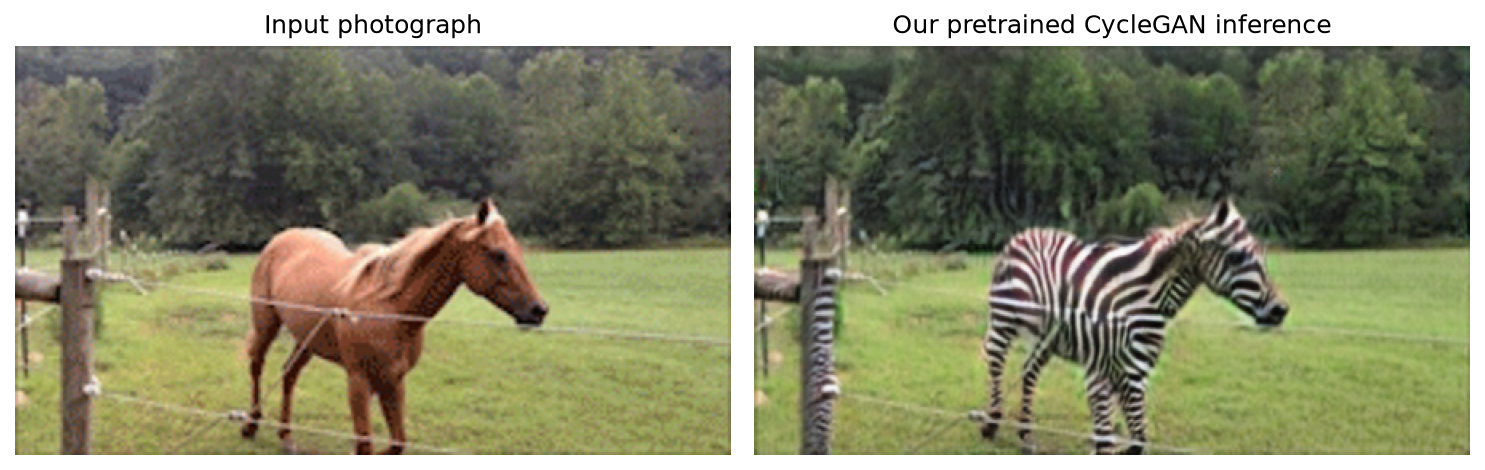

Cached pretrained inference; CPU forward time: 1.739 s. No training performed.


In [14]:
#@title Verified saved photo experiment
import base64
from IPython.display import Image as DisplayImage, display
PHOTO_INPUT_BASE64 = "..."
PHOTO_PREVIEW_BASE64 = "..."
display(DisplayImage(data=base64.b64decode(PHOTO_PREVIEW_BASE64)))
print("Cached pretrained inference; CPU forward time: 1.739 s. No training performed.")

In [15]:
#@title Optional live photo inference
RUN_CYCLEGAN_DEMO = False #@param {type:"boolean"}

"""Run the optional official pretrained CycleGAN photo experiment.

Architecture code is downloaded from an immutable upstream commit; it is not
included in this package. The source input is the left panel of upstream's
horse2zebra demonstration, first frame. No original training is performed.
"""

import argparse
import hashlib
import importlib.util
import json
from pathlib import Path
import time
import urllib.request

import numpy as np
from PIL import Image
import torch


REPO_SHA = "2a7afba2895d52556dd5dfe07e8555ef657ced6f"
SOURCE_HASH = "2bfcb7adb19f7b7ff6fd8dd76e313200acf000e96784b920658a62e1a11fc04f"
SOURCE_URL = f"https://raw.githubusercontent.com/junyanz/pytorch-CycleGAN-and-pix2pix/{REPO_SHA}/models/networks.py"
MODEL_URL = "https://efrosgans.eecs.berkeley.edu/cyclegan/pretrained_models/horse2zebra.pth"
MODEL_HASH = "5bfc34b154035be1cd592cd273fdf328810bee4756044c9cf7deb8d4b6d2fadb"
IMAGE_URL = f"https://raw.githubusercontent.com/junyanz/pytorch-CycleGAN-and-pix2pix/{REPO_SHA}/imgs/horse2zebra.gif"


def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def download(url, target, expected_hash=None):
    target = Path(target)
    if not target.exists():
        temporary = target.with_suffix(target.suffix + ".download")
        with urllib.request.urlopen(url, timeout=90) as response, temporary.open("wb") as output:
            while chunk := response.read(1024 * 1024):
                output.write(chunk)
        temporary.replace(target)
    if expected_hash is not None and file_hash(target) != expected_hash:
        raise ValueError(f"Checksum mismatch: {target.name}")
    return target


def translate(image, cache, device="cpu"):
    cache = Path(cache)
    cache.mkdir(parents=True, exist_ok=True)
    source = download(SOURCE_URL, cache / "networks.py", SOURCE_HASH)
    weights_path = download(MODEL_URL, cache / "horse2zebra.pth", MODEL_HASH)
    spec = importlib.util.spec_from_file_location("official_cyclegan_networks", source)
    networks = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(networks)
    network = networks.ResnetGenerator(
        3, 3, ngf=64,
        norm_layer=torch.nn.InstanceNorm2d,
        use_dropout=False, n_blocks=9,
    )
    weights = torch.load(weights_path, map_location="cpu", weights_only=True)
    # Older InstanceNorm checkpoints contain buffers that current PyTorch omits.
    weights = {
        key: value for key, value in weights.items()
        if not key.endswith(("running_mean", "running_var", "num_batches_tracked"))
    }
    network.load_state_dict(weights, strict=True)
    network = network.to(device).eval()
    pixels = np.array(image.convert("RGB"), dtype=np.float32) / 127.5 - 1
    tensor = torch.from_numpy(pixels).permute(2, 0, 1).unsqueeze(0).to(device)
    started = time.perf_counter()
    with torch.inference_mode():
        result = network(tensor).clamp(-1, 1)
    elapsed = time.perf_counter() - started
    result = ((result[0].permute(1, 2, 0).cpu().numpy() + 1) * 127.5).round().astype("uint8")
    return Image.fromarray(result), elapsed



if RUN_CYCLEGAN_DEMO:
    from io import BytesIO
    photo_input = Image.open(BytesIO(base64.b64decode(PHOTO_INPUT_BASE64))).convert("RGB")
    photo_device = "cuda" if torch.cuda.is_available() else "cpu"
    photo_prediction, photo_seconds = translate(photo_input, Path.cwd() / "cyclegan_cache", device=photo_device)
    display(photo_prediction)
    print(f"New pretrained forward pass: {photo_seconds:.3f} s on {photo_device}")
else:
    print("Live photo inference disabled. The verified cached result is shown above.")


Live photo inference disabled. The verified cached result is shown above.


## Фотографии кошки и собаки: латентное представление

- **Данные:** две реальные фотографии, центрированный crop 256×256; атрибуция — [Wikimedia Commons](https://commons.wikimedia.org/).
- **Модель:** [TAESD](https://github.com/madebyollin/taesd), предобученный компактный автоэнкодер. Первоначальная загрузка весов — около 10 MB.
- **Эксперимент:** восстановление $D(E(x))$ и возмущение кода $D(E(x)+\sigma\varepsilon)$; параметры доступны ниже.
- TAESD детерминирован: гауссовский posterior и генеративный prior здесь не обучаются. Случайный код не является корректным источником новых фотографий.
- Линейное смешение кодов кошки и собаки может создавать гибридные признаки. Для заданного класса нужно обученное условие $y$; это показано на MNIST в cVAE, cGAN и DDPM.
- **Задание:** сопоставить сохранение формы и мелких деталей при разных $\sigma$. Различить случайность внутри класса и смену класса.

**Теория:** [Латентная диффузия: роль автоэнкодера](https://fpakhurov.com/ru/notes/generative-models/latent-diffusion/), [условный перевод доменов](https://fpakhurov.com/ru/notes/generative-models/stargan/).

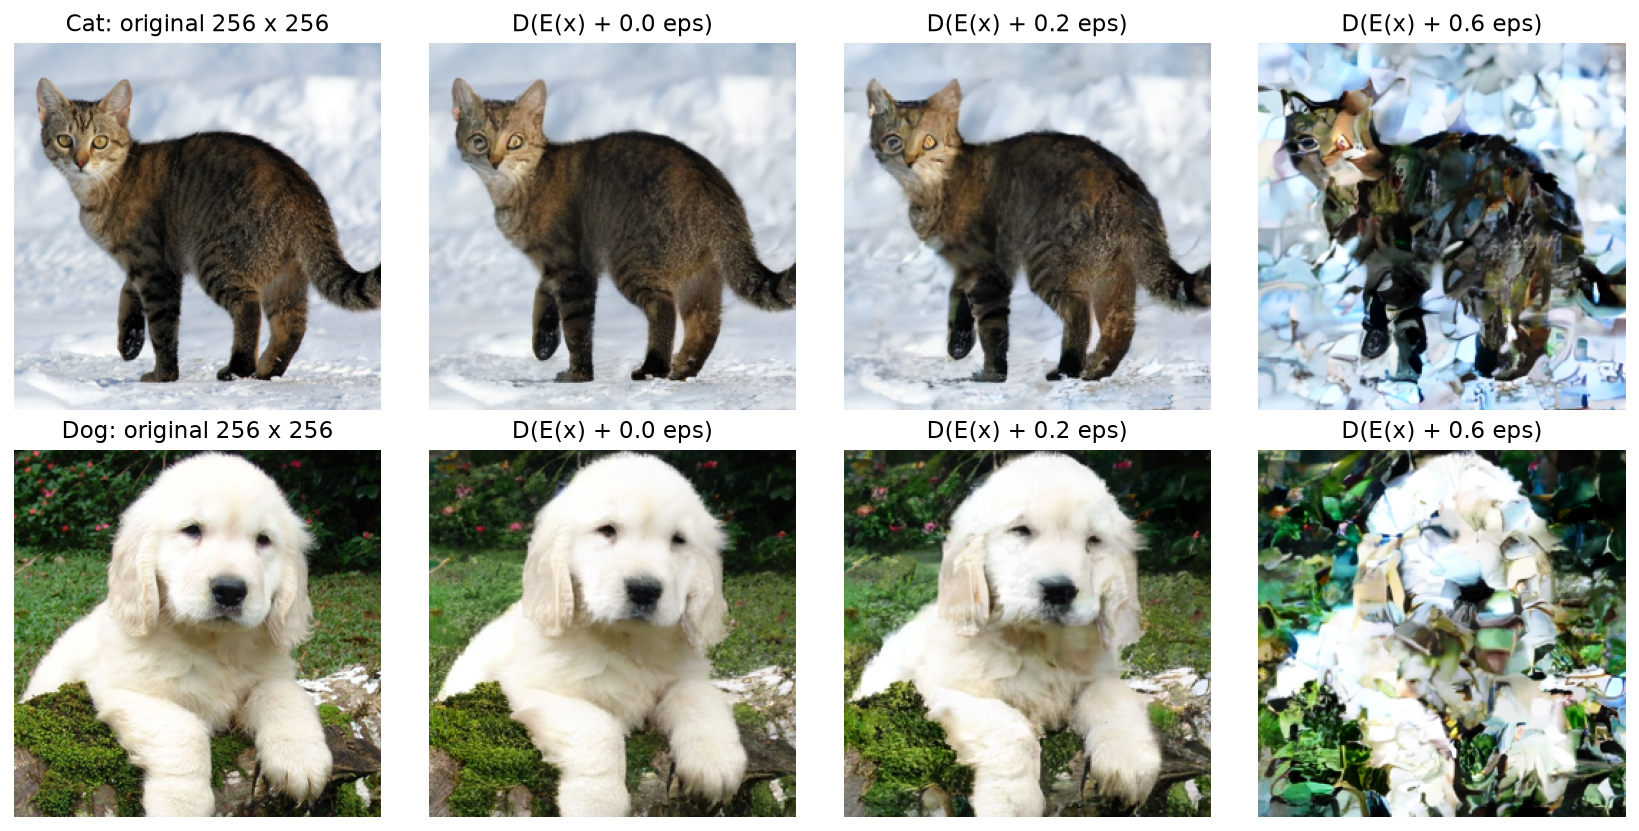

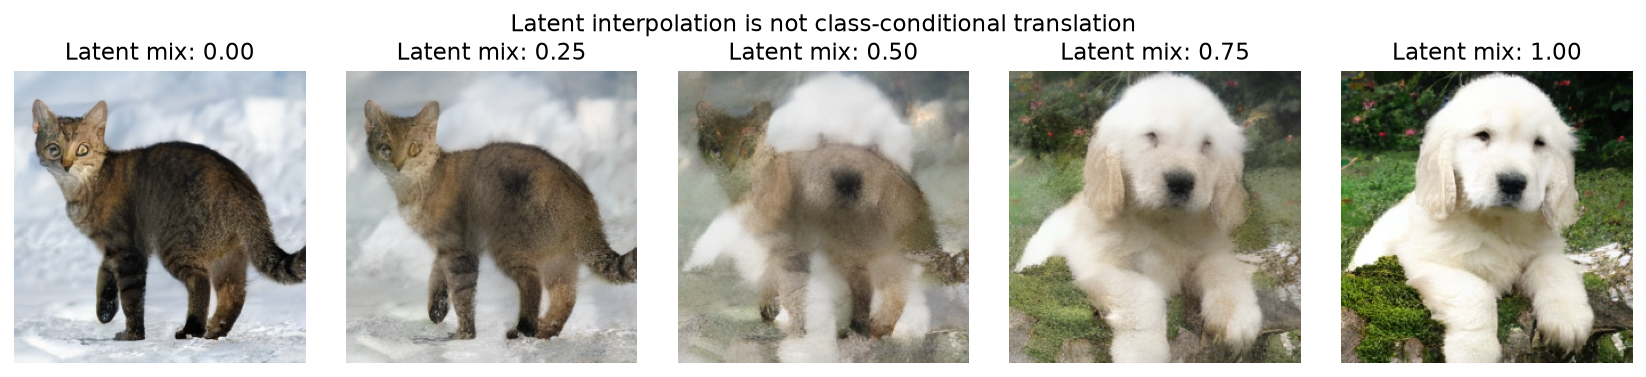

Pet demo: [2, 3, 256, 256] -> [2, 4, 32, 32] ; reconstruction MSE: [0.0025059052277356386, 0.005918176379054785]


In [16]:
#@title Real cat and dog: reconstruction and latent perturbation
RUN_PET_DEMO = True #@param {type:"boolean"}
PET_NOISE = 0.2 #@param {type:"slider", min:0.05, max:0.6, step:0.05}

"""Reconstruct real cat/dog photos using a small pretrained image autoencoder."""

from pathlib import Path
import hashlib
import importlib.util
import json
import time
import urllib.request

import numpy as np
from PIL import Image, ImageOps
import torch

PET_MODEL_COMMIT = "fdbae2df989db95761f482efb8977e1182fb68d2"
PET_HASHES = {'taesd.py': '5943493eb291f768e0a87dd9b54c60461d3be0a9141003db7f62bd6b8e9efa6f', 'taesd_encoder.pth': '15bc6128f0ac51c673d3427216082ebfa62402ffc89763af74edfe259b32d49d', 'taesd_decoder.pth': '02873377c3f4659cd9f9adb2f718dcb434ba4c7bba3af3ee7bb95cbdabe2d3cf', 'cat.jpg': '74d09a7c6463a844572c58634a798d4fa1b646aeff8be81a42ab68915e54e049', 'dog.jpg': '1e71abf29876f248088a11211a350ed3d26a0c68aa34f6e45738771eb2d45a22'}
PET_URLS = {
    "taesd.py": f"https://raw.githubusercontent.com/madebyollin/taesd/{PET_MODEL_COMMIT}/taesd.py",
    "taesd_encoder.pth": f"https://raw.githubusercontent.com/madebyollin/taesd/{PET_MODEL_COMMIT}/taesd_encoder.pth",
    "taesd_decoder.pth": f"https://raw.githubusercontent.com/madebyollin/taesd/{PET_MODEL_COMMIT}/taesd_decoder.pth",
    "cat.jpg": "https://upload.wikimedia.org/wikipedia/commons/b/b6/Felis_catus-cat_on_snow.jpg",
    "dog.jpg": "https://upload.wikimedia.org/wikipedia/commons/6/6e/Golde33443.jpg",
}


def pet_download(name, cache):
    path = Path(cache) / name
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        request = urllib.request.Request(PET_URLS[name], headers={"User-Agent": "EducationalSeminar/1.0"})
        with urllib.request.urlopen(request, timeout=90) as response:
            path.write_bytes(response.read())
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    expected = PET_HASHES.get(name)
    if expected and digest != expected:
        raise ValueError(f"Pet demo checksum mismatch: {name}")
    return path


def run_pet_demo(cache="data/pets", noise_levels=(0.0, 0.2, 0.6), seed=42):
    cache = Path(cache)
    files = {name: pet_download(name, cache) for name in PET_URLS}
    spec = importlib.util.spec_from_file_location("official_taesd", files["taesd.py"])
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    model = module.TAESD(encoder_path=str(files["taesd_encoder.pth"]), decoder_path=str(files["taesd_decoder.pth"]), latent_channels=4, image_channels=3).eval()
    originals = [ImageOps.fit(Image.open(files[name]).convert("RGB"), (256, 256), method=Image.Resampling.LANCZOS) for name in ["cat.jpg", "dog.jpg"]]
    x = torch.tensor(np.stack([np.asarray(im, dtype="float32") / 255 for im in originals])).permute(0, 3, 1, 2)
    generator = torch.Generator().manual_seed(seed)
    start = time.perf_counter()
    with torch.inference_mode():
        z = model.encoder(x)
        noise = torch.randn(z.shape, generator=generator)
        decoded = [model.decoder(z + float(level) * noise).clamp(0, 1) for level in noise_levels]
        weights = torch.linspace(0, 1, 5).view(-1, 1, 1, 1)
        latent_path = (1 - weights) * z[:1] + weights * z[1:2]
        interpolated = model.decoder(latent_path).clamp(0, 1)
    report = {
        "method": "TAESD deterministic distilled image autoencoder",
        "model_commit": PET_MODEL_COMMIT,
        "input_shape": list(x.shape),
        "latent_shape": list(z.shape),
        "noise_levels": list(noise_levels),
        "reconstruction_mse": [float((decoded[0][i] - x[i]).square().mean()) for i in range(2)],
        "seconds_cpu": round(time.perf_counter() - start, 3),
        "training_performed": False,
        "gaussian_posterior": False,
        "files": {name: {"url": PET_URLS[name], "sha256": hashlib.sha256(path.read_bytes()).hexdigest()} for name, path in files.items()},
    }
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(2, 1 + len(decoded), figsize=(12, 6), dpi=140)
    for row, label in enumerate(["Cat", "Dog"]):
        axes[row, 0].imshow(originals[row])
        axes[row, 0].set_title(label + ": original 256 x 256")
        for col, (level, result) in enumerate(zip(noise_levels, decoded), start=1):
            axes[row, col].imshow(result[row].permute(1, 2, 0).numpy())
            axes[row, col].set_title(f"D(E(x) + {level:.1f} eps)")
    for axis in axes.flat:
        axis.axis("off")
    fig.tight_layout()
    fig2, axes2 = plt.subplots(1, 5, figsize=(12, 2.7), dpi=140)
    for index, axis in enumerate(axes2):
        axis.imshow(interpolated[index].permute(1, 2, 0).numpy())
        axis.set_title(f"Latent mix: {index / 4:.2f}")
        axis.axis("off")
    fig2.suptitle("Latent interpolation is not class-conditional translation")
    fig2.tight_layout()
    return fig, fig2, report



if RUN_PET_DEMO:
    from IPython.display import display
    import matplotlib.pyplot as plt
    pet_figures = run_pet_demo(noise_levels=(0.0, PET_NOISE, 3 * PET_NOISE))
    display(pet_figures[0]); display(pet_figures[1])
    plt.close(pet_figures[0]); plt.close(pet_figures[1])
    print("Pet demo:", pet_figures[2]["input_shape"], "->", pet_figures[2]["latent_shape"], "; reconstruction MSE:", pet_figures[2]["reconstruction_mse"])
else:
    print("Optional pet experiment disabled.")


## 11. Прикладные постановки

| Задача | Проверка |
|---|---|
| Синтетические изображения редких дефектов | Метрика на независимых реальных данных |
| Восстановление пропусков | Согласие с наблюдением, неопределённость |
| Компактные признаки | Сохранение информации, переносимость |
| Перевод между камерами | Сохранение дефектов и геометрии |

Результаты на данных Газпрома не получены. Reconstruction error и likelihood сами по себе не подтверждают пригодность детектора аномалий.

### Контрольные задания

1. Указать процедуру генерации VAE без encoder.
2. Различить `exp(logvar)` и `exp(0.5 * logvar)`.
3. Объяснить размещение `detach` в шагах D и G.
4. Указать независимую проверку пользы синтетики.

<details><summary>Ответы</summary>

1. $z\sim\mathcal N(0,I)$ → decoder; здесь визуализируется среднее likelihood.
2. Дисперсия и стандартное отклонение соответственно.
3. В шаге D отсекается градиент в G; в шаге G сохраняется путь через D.
4. Downstream-метрика на реальных отложенных данных.

</details>

**Следующий семинар:** точная плотность через обратимые преобразования; генерация через последовательное удаление шума.

## Источники

- [HSE-LAMBDA · Deep Generative Models](https://github.com/HSE-LAMBDA/DeepGenerativeModels/tree/spring-2025-long).
- [Kingma & Welling · VAE](https://arxiv.org/abs/1312.6114).
- [Goodfellow et al. · GAN](https://arxiv.org/abs/1406.2661).
- [Zhu et al. · CycleGAN](https://arxiv.org/abs/1703.10593).
- [MNIST: рукописные цифры](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html).

Реализации написаны для семинара; архитектурные схемы из внешних источников иллюстрируют общий принцип.